# 2 - Exploratory Data Analysis (EDA)

## Hotel Booking Cancellation Prediction

This notebook is prepared for the EDA stage of the IT3051 FDM Mini Project. Members 1 and 2 have completed their sections. Member 3 retains a placeholder.

## EDA Objective

The purpose of EDA is to explore the Hotel Booking dataset to identify cancellation-related patterns, feature distributions, unusual observations, and potential feature-engineering opportunities. Findings from this stage will guide preprocessing, feature engineering, feature selection, and future modelling decisions.

## Import Libraries and Load Dataset

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 120)
sns.set_theme(style='whitegrid', palette='Set2')

DATA_PATH = Path('../data/raw/hotel_booking.csv')
FIGURE_DIR = Path('Figures/stay_reservation')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## Helper Functions

In [5]:
def cancellation_rate_table(data, column):
    summary = (
        data.groupby(column, dropna=False)['is_canceled']
        .agg(total_bookings='count', canceled_bookings='sum', cancellation_rate='mean')
        .reset_index()
    )
    summary['cancellation_rate'] = (summary['cancellation_rate'] * 100).round(2)
    return summary.sort_values('cancellation_rate', ascending=False)

def save_current_figure(filename):
    path = FIGURE_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved figure: {path}')

## Overall Target Distribution

This gives context for all members’ target comparisons. A cancellation rate of the full dataset is useful as a baseline.

In [6]:
target_summary = df['is_canceled'].value_counts().sort_index().reset_index()
target_summary.columns = ['is_canceled', 'count']
target_summary['meaning'] = target_summary['is_canceled'].map({0: 'Not canceled', 1: 'Canceled'})
target_summary['percentage'] = (target_summary['count'] / len(df) * 100).round(2)
target_summary

,is_canceled,count,meaning,percentage
0,0,75166,Not canceled,62.96
1,1,44224,Canceled,37.04


## Member 1 - Booking & Customer Behaviour Analysis

This section examines all eight assigned variables using the original booking rows.
`is_canceled`: **0 = not canceled; 1 = canceled**. Counts describe bookings, not unique customers.
Distributions, target comparisons, and unusual observations are descriptive associations, not causal effects.
No rows are removed, imputed, capped, or transformed in the source dataset. Groupings and log views are for EDA only.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Supports running from either the repository root or the notebook folder.
m1_root = Path.cwd() if (Path.cwd() / 'data/raw/hotel_booking.csv').exists() else Path.cwd().parent
m1_figures = m1_root / '02_EDA/Figures/booking_customer'
m1_figures.mkdir(parents=True, exist_ok=True)
m1_numeric = ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled',
              'booking_changes', 'days_in_waiting_list', 'total_of_special_requests']
m1_columns = m1_numeric + ['is_repeated_guest', 'customer_type']
m1 = pd.read_csv(m1_root / 'data/raw/hotel_booking.csv',
                 usecols=m1_columns + ['is_canceled', 'hotel'])
assert m1['is_canceled'].notna().all() and m1['is_canceled'].isin([0, 1]).all()
m1_baseline = m1['is_canceled'].mean() * 100
sns.set_theme(style='whitegrid', palette='Set2')
print(f'{len(m1):,} bookings; {m1.is_canceled.sum():,} canceled; baseline = {m1_baseline:.2f}%.')

def m1_show(table, _name):
    display(table.round(3))

def m1_rates(data, column):
    table = data.groupby(column, observed=True, dropna=False)['is_canceled'].agg(
        bookings='size', canceled='sum').reset_index()
    n = table['bookings']
    p = table['canceled'] / n
    z = 1.96
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    table['share_pct'] = n / len(data) * 100
    table['cancellation_rate_pct'] = p * 100
    table['ci95_low_pct'] = (center - half) * 100
    table['ci95_high_pct'] = (center + half) * 100
    return table

def m1_save(fig, name):
    fig.tight_layout()
    fig.savefig(m1_figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)

def m1_rate_plot(table, ax, title):
    x = np.arange(len(table))
    rate = table['cancellation_rate_pct'].to_numpy()
    ax.bar(x, rate, color='#4097a5')
    ax.errorbar(x, rate, yerr=np.maximum(0, np.array([
        rate - table.ci95_low_pct, table.ci95_high_pct - rate])),
        fmt='none', color='#333333', capsize=3)
    ax.axhline(m1_baseline, color='#b34b43', linestyle='--', label=f'Overall {m1_baseline:.2f}%')
    ax.set_xticks(x, [f'{v}\n(n={n:,})' for v, n in zip(table.iloc[:, 0], table.bookings)],
                  rotation=25, ha='right')
    ax.set_ylim(0, 108)
    ax.set_ylabel('Canceled bookings (%)')
    ax.set_title(title + ' (95% Wilson intervals)')
    ax.legend(fontsize=8)

m1_bins = {
    'lead_time': ([-1, 0, 7, 30, 90, 180, 365, np.inf], ['0', '1–7', '8–30', '31–90', '91–180', '181–365', '366+']),
    'previous_cancellations': ([-1, 0, 1, 2, 5, np.inf], ['0', '1', '2', '3–5', '6+']),
    'previous_bookings_not_canceled': ([-1, 0, 1, 2, 5, np.inf], ['0', '1', '2', '3–5', '6+']),
    'booking_changes': ([-1, 0, 1, 2, 5, np.inf], ['0', '1', '2', '3–5', '6+']),
    'days_in_waiting_list': ([-1, 0, 7, 30, 90, np.inf], ['0', '1–7', '8–30', '31–90', '91+']),
}
m1_group_tables = {}
m1_group_columns = {}

def m1_analyse(column, title):
    series = m1[column]
    m1_show(m1_rates(m1, column), column + '_exact_values')
    if column in m1_bins:
        edges, labels = m1_bins[column]
        group = column + '_group'
        m1[group] = pd.cut(series, edges, labels=labels)
    else:
        group = column
    table = m1_rates(m1, group)
    m1_group_tables[column] = table
    m1_group_columns[column] = group
    m1_show(table, column + '_target_groups')
    if column in m1_numeric:
        fig, axes = plt.subplots(2, 2, figsize=(14, 9))
        if column == 'total_of_special_requests':
            counts = series.value_counts().sort_index()
            axes[0, 0].bar(counts.index, counts.values)
            axes[0, 0].set_xticks(counts.index)
        else:
            axes[0, 0].hist(series, bins=45, color='#4097a5')
        axes[0, 0].set(xlabel=column, ylabel='Bookings', title='Full range distribution (zeros included)')
        if column == 'total_of_special_requests':
            sns.countplot(data=m1, x=column, hue='is_canceled', ax=axes[0, 1])
            axes[0, 1].set_title('Counts by target: 0 = not canceled, 1 = canceled')
        else:
            axes[0, 1].hist(np.log1p(series[series > 0]), bins=35, color='#d99555')
            axes[0, 1].set(xlabel='log(1 + value)', ylabel='Bookings',
                           title=f'Positive values only (n={(series > 0).sum():,})')
        sns.boxplot(data=m1, x='is_canceled', y=column, ax=axes[1, 0], fliersize=2)
        axes[1, 0].set(xlabel='Target: 0 = not canceled, 1 = canceled', title='Full range by target; outliers retained')
        m1_rate_plot(table, axes[1, 1], 'Cancellation by value/group')
    else:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.countplot(data=m1, x=column, order=table.iloc[:, 0].tolist(), hue='is_canceled', ax=axes[0])
        axes[0].set_title('Booking counts: 0 = not canceled, 1 = canceled')
        axes[0].tick_params(axis='x', rotation=25)
        m1_rate_plot(table, axes[1], 'Cancellation by category')
    fig.suptitle(title, fontsize=15)
    m1_save(fig, column)


119,390 bookings; 44,224 canceled; baseline = 37.04%.


### 1.1 Data quality and numerical distributions

The summary includes missingness, zero prevalence, quantiles, skewness, and domain checks.
Repeated guest is a binary category, so an IQR outlier rule is inappropriate for it.
Exact-value tables and binned target tables accompany each variable. Bins are explicit, right-closed
descriptive choices; they are not learned thresholds. Error bars are approximate booking-level 95%
Wilson intervals. They assume independent rows; repeated customers or group bookings can make them too narrow.


In [2]:
m1_quality = pd.DataFrame({
    'variable': m1_columns,
    'dtype': [str(m1[c].dtype) for c in m1_columns],
    'missing': [m1[c].isna().sum() for c in m1_columns],
    'unique_values': [m1[c].nunique() for c in m1_columns],
})
m1_show(m1_quality, 'data_quality')
m1_stats = m1[m1_numeric].describe(percentiles=[.25, .5, .75, .95, .99]).T
m1_stats['zero_count'] = m1[m1_numeric].eq(0).sum()
m1_stats['zero_pct'] = m1[m1_numeric].eq(0).mean() * 100
m1_stats['skewness'] = m1[m1_numeric].skew()
m1_stats['negative_count'] = m1[m1_numeric].lt(0).sum()
m1_stats['fractional_count'] = m1[m1_numeric].mod(1).ne(0).sum()
m1_show(m1_stats.rename_axis('variable').reset_index(), 'numeric_distribution_summary')
m1_by_target = m1.groupby('is_canceled')[m1_numeric].agg(['count', 'mean', 'median', 'max'])
m1_by_target.columns = ['_'.join(c) for c in m1_by_target.columns]
m1_show(m1_by_target.reset_index(), 'numeric_summary_by_target')


,variable,dtype,missing,unique_values
0,lead_time,int64,0,479
1,previous_cancellations,int64,0,15
2,previous_bookings_not_canceled,int64,0,73
3,booking_changes,int64,0,21
4,days_in_waiting_list,int64,0,128
5,total_of_special_requests,int64,0,6
6,is_repeated_guest,int64,0,2
7,customer_type,str,0,4


,variable,count,mean,std,min,25%,50%,75%,95%,99%,max,zero_count,zero_pct,skewness,negative_count,fractional_count
0,lead_time,119390.0,104.011,106.863,0.0,18.0,69.0,160.0,320.0,444.0,737.0,6345,5.315,1.347,0,0
1,previous_cancellations,119390.0,0.087,0.844,0.0,0.0,0.0,0.0,1.0,1.0,26.0,112906,94.569,24.458,0,0
2,previous_bookings_not_canceled,119390.0,0.137,1.497,0.0,0.0,0.0,0.0,0.0,3.0,72.0,115770,96.968,23.540,0,0
3,booking_changes,119390.0,0.221,0.652,0.0,0.0,0.0,0.0,1.0,3.0,21.0,101314,84.860,6.000,0,0
4,days_in_waiting_list,119390.0,2.321,17.595,0.0,0.0,0.0,0.0,0.0,75.0,391.0,115692,96.903,11.944,0,0
5,total_of_special_requests,119390.0,0.571,0.793,0.0,0.0,0.0,1.0,2.0,3.0,5.0,70318,58.898,1.349,0,0


,is_canceled,lead_time_count,lead_time_mean,lead_time_median,lead_time_max,previous_cancellations_count,previous_cancellations_mean,previous_cancellations_median,previous_cancellations_max,previous_bookings_not_canceled_count,...,booking_changes_median,booking_changes_max,days_in_waiting_list_count,days_in_waiting_list_mean,days_in_waiting_list_median,days_in_waiting_list_max,total_of_special_requests_count,total_of_special_requests_mean,total_of_special_requests_median,total_of_special_requests_max
0,0,75166,79.985,45.0,737,75166,0.016,0.0,13,75166,...,0.0,21,75166,1.590,0.0,379,75166,0.714,1.0,5
1,1,44224,144.849,113.0,629,44224,0.208,0.0,26,44224,...,0.0,16,44224,3.564,0.0,391,44224,0.329,0.0,5


### 1.2 Lead time

Compare same-day, short-lead and long-lead bookings. The full tail stays visible; a positive-only log view makes the skew easier to inspect.

,lead_time,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,6345,430,5.315,6.777,6.184,7.422
1,1,3460,321,2.898,9.277,8.355,10.290
2,2,2069,213,1.733,10.295,9.058,11.679
3,3,1816,182,1.521,10.022,8.724,11.489
4,4,1715,176,1.436,10.262,8.914,11.789
...,...,...,...,...,...,...,...
474,622,17,17,0.014,100.000,81.568,100.000
475,626,30,30,0.025,100.000,88.648,100.000
476,629,17,17,0.014,100.000,81.568,100.000
477,709,1,0,0.001,0.000,0.000,79.346


,lead_time_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,6345,430,5.315,6.777,6.184,7.422
1,1–7,13401,1472,11.225,10.984,10.466,11.525
2,8–30,18960,5283,15.881,27.864,27.230,28.507
3,31–90,29553,11141,24.753,37.698,37.147,38.252
4,91–180,26439,11821,22.145,44.710,44.112,45.311
5,181–365,21544,11947,18.045,55.454,54.789,56.117
6,366+,3148,2130,2.637,67.662,66.007,69.274


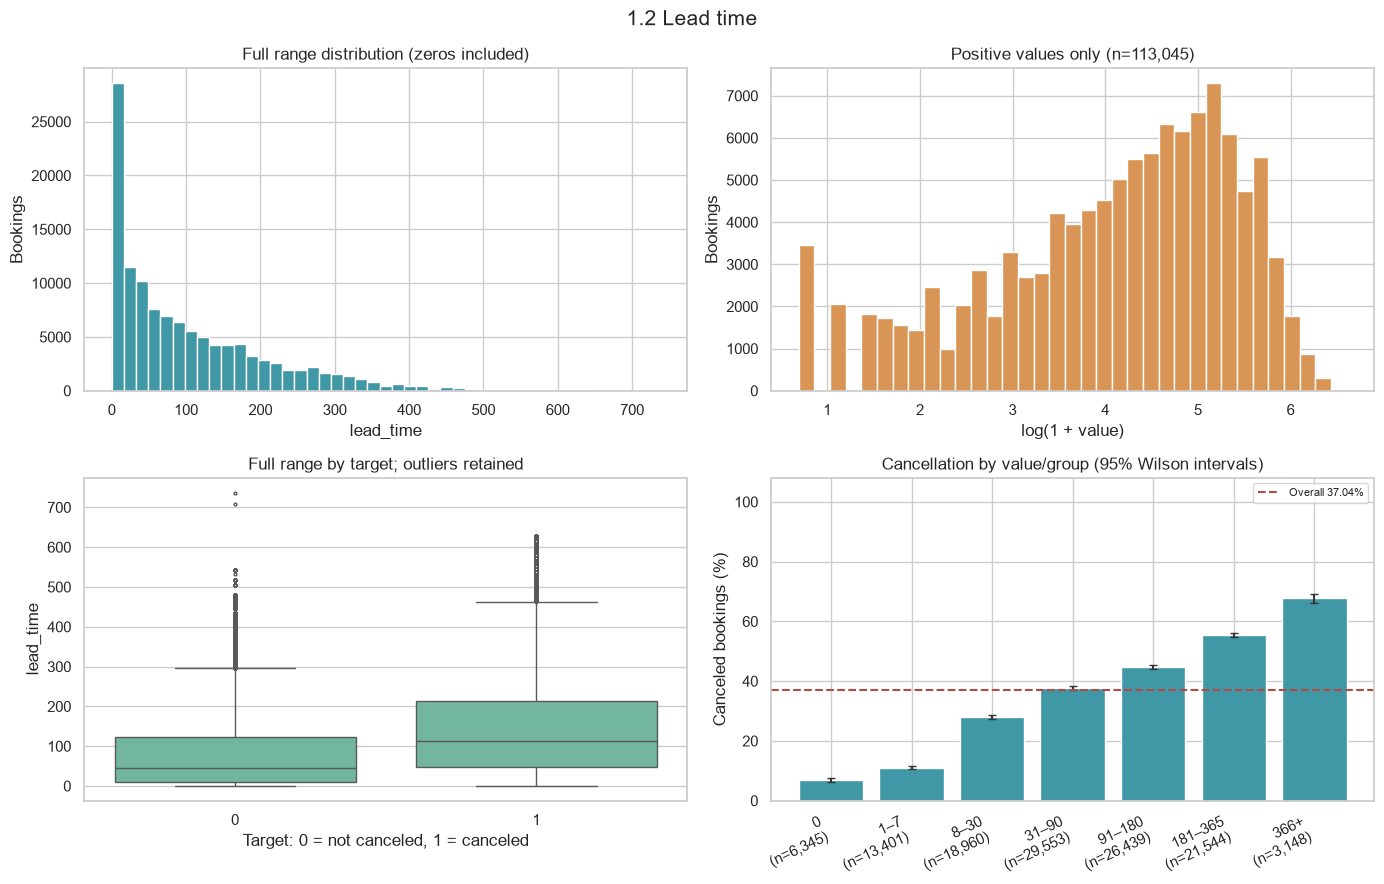

In [3]:
m1_analyse('lead_time', '1.2 Lead time')

**Finding:** Median lead time is 69 days, compared with a mean of 104.01 and a maximum of 737. The distribution has a long right tail. Cancellation rises from 6.78% for same-day bookings to 67.66% for bookings made over a year ahead.

### 1.3 Previous cancellations

Distinguish no recorded cancellations from a cancellation history, and inspect individual counts before interpreting pooled tail groups. The relationship need not be monotonic.

,previous_cancellations,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,112906,38282,94.569,33.906,33.631,34.183
1,1,6051,5714,5.068,94.431,93.824,94.981
2,2,116,38,0.097,32.759,24.890,41.732
3,3,65,20,0.054,30.769,20.887,42.798
4,4,31,7,0.026,22.581,11.395,39.813
5,5,19,2,0.016,10.526,2.936,31.395
6,6,22,7,0.018,31.818,16.360,52.682
7,11,35,10,0.029,28.571,16.326,45.055
8,13,12,11,0.010,91.667,64.611,98.514
9,14,14,14,0.012,100.000,78.468,100.000


,previous_cancellations_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,112906,38282,94.569,33.906,33.631,34.183
1,1,6051,5714,5.068,94.431,93.824,94.981
2,2,116,38,0.097,32.759,24.890,41.732
3,3–5,115,29,0.096,25.217,18.170,33.867
4,6+,202,161,0.169,79.703,73.626,84.671


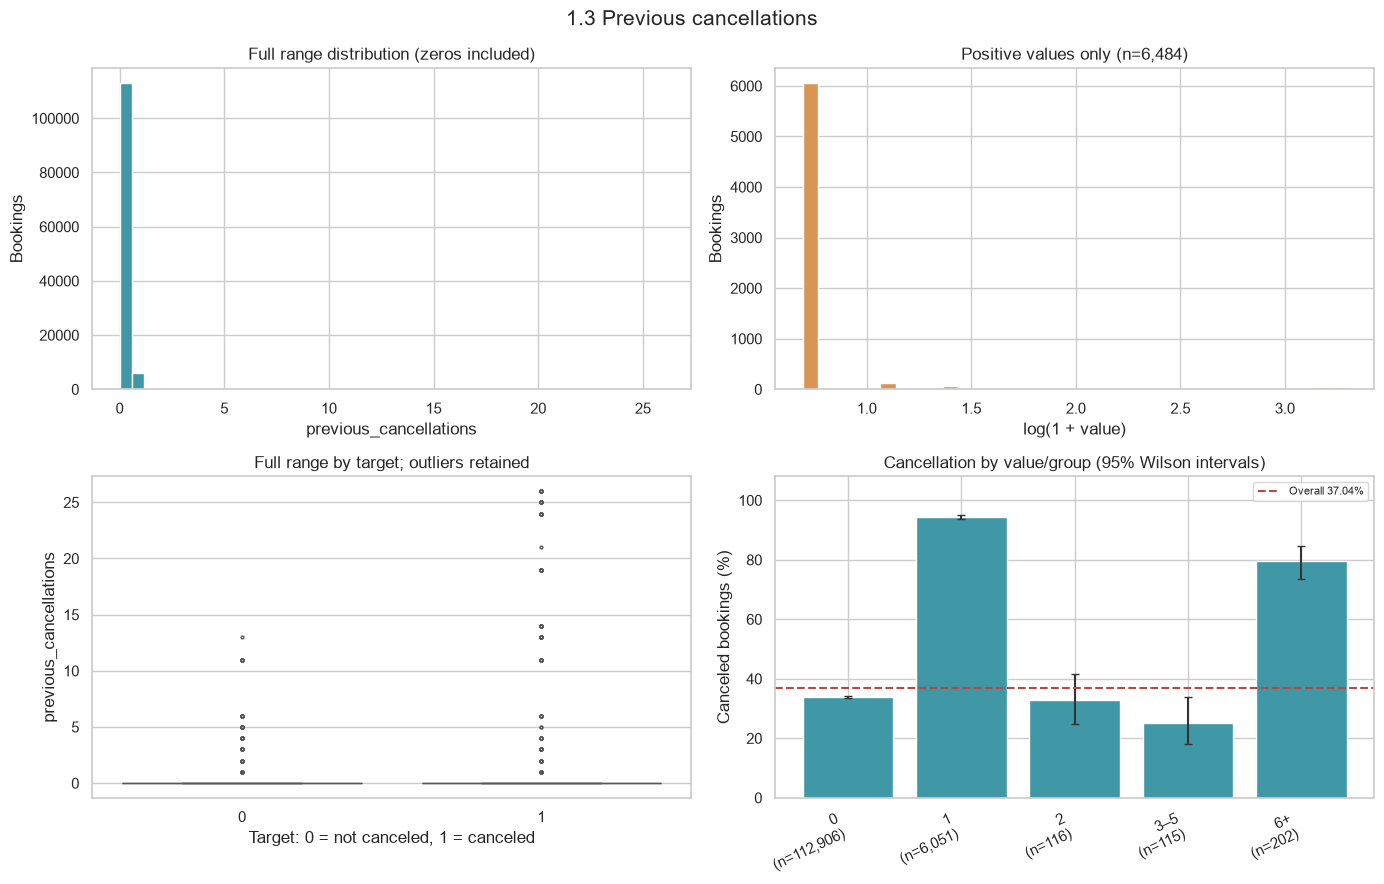

In [4]:
m1_analyse('previous_cancellations', '1.3 Previous cancellations')

**Finding:** 94.57% have no previous cancellations. Bookings with a cancellation history cancel at 91.64%, versus 33.91% without one. The relationship is not monotonic: exactly one prior cancellation has a 94.43% rate, compared with 32.76% for two.

### 1.4 Previous bookings not canceled

Zero means no recorded non-canceled booking history; it is not a missing value. High counts can represent frequent guests.

,previous_bookings_not_canceled,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115770,44024,96.968,38.027,37.748,38.307
1,1,1542,79,1.292,5.123,4.130,6.339
2,2,580,32,0.486,5.517,3.935,7.685
3,3,333,17,0.279,5.105,3.211,8.023
4,4,229,12,0.192,5.240,3.023,8.935
...,...,...,...,...,...,...,...
68,68,1,0,0.001,0.000,0.000,79.346
69,69,1,0,0.001,0.000,0.000,79.346
70,70,1,0,0.001,0.000,0.000,79.346
71,71,1,0,0.001,0.000,0.000,79.346


,previous_bookings_not_canceled_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115770,44024,96.968,38.027,37.748,38.307
1,1,1542,79,1.292,5.123,4.130,6.339
2,2,580,32,0.486,5.517,3.935,7.685
3,3–5,743,40,0.622,5.384,3.978,7.248
4,6+,755,49,0.632,6.490,4.944,8.477


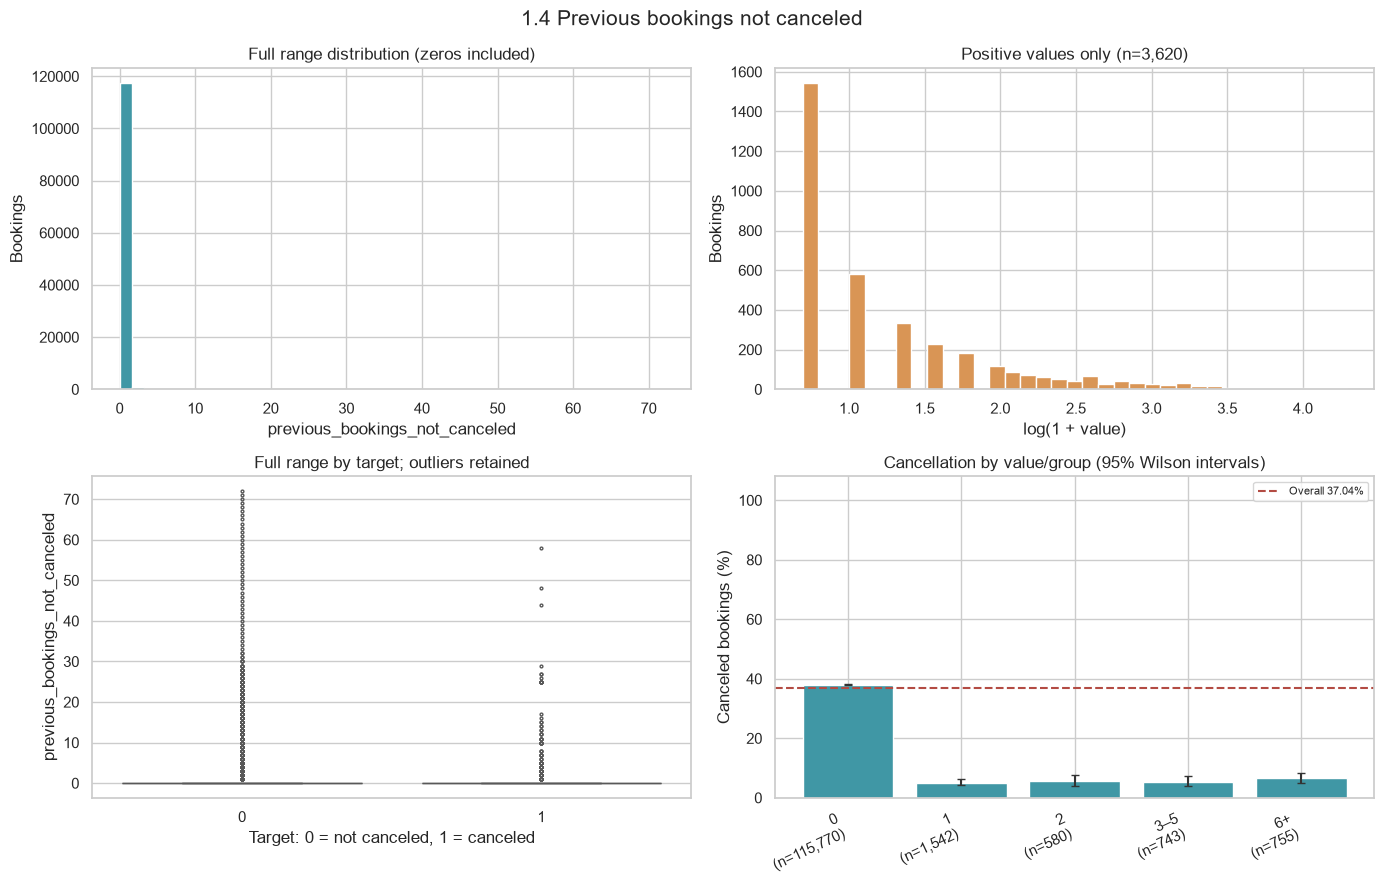

In [5]:
m1_analyse('previous_bookings_not_canceled', '1.4 Previous bookings not canceled')

**Finding:** 96.97% have no recorded non-canceled bookings. Bookings with this history cancel at 5.52%, compared with 38.03% without it. The maximum history count is 72.

### 1.5 Repeated guest

Treat 0 and 1 as categories. Compare category frequency and cancellation rate; the minority group has a different sample size.

,is_repeated_guest,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115580,43672,96.809,37.785,37.506,38.065
1,1,3810,552,3.191,14.488,13.406,15.642


,is_repeated_guest,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115580,43672,96.809,37.785,37.506,38.065
1,1,3810,552,3.191,14.488,13.406,15.642


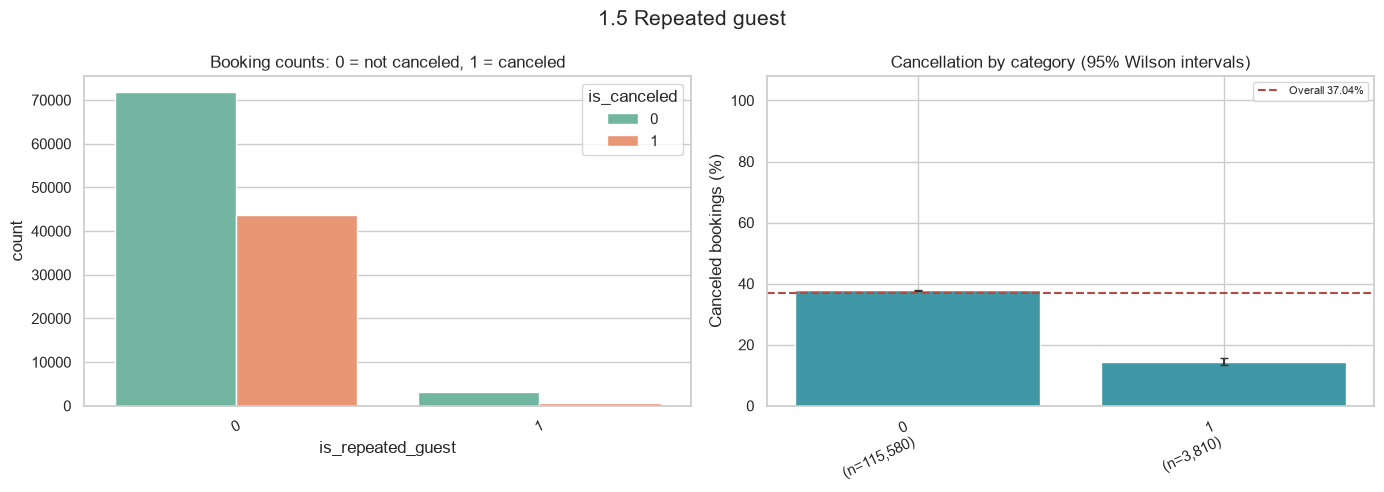

In [6]:
m1_analyse('is_repeated_guest', '1.5 Repeated guest')

**Finding:** Repeated guests account for 3.19% of bookings. Their cancellation rate is 14.49%, compared with 37.79% for other bookings. Review the history cross-check before treating this flag as equivalent to recorded booking history.

### 1.6 Booking changes

Changes can accumulate after creation. An association with cancellation does not establish that making changes prevents cancellation.

,booking_changes,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,101314,41391,84.860,40.854,40.552,41.157
1,1,12701,1807,10.638,14.227,13.631,14.846
2,2,3805,766,3.187,20.131,18.888,21.435
3,3,927,144,0.776,15.534,13.345,18.008
4,4,376,67,0.315,17.819,14.282,22.007
5,5,118,20,0.099,16.949,11.248,24.734
6,6,63,18,0.053,28.571,18.903,40.703
7,7,31,3,0.026,9.677,3.346,24.900
8,8,17,4,0.014,23.529,9.555,47.262
9,9,8,1,0.007,12.500,2.242,47.089


,booking_changes_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,101314,41391,84.860,40.854,40.552,41.157
1,1,12701,1807,10.638,14.227,13.631,14.846
2,2,3805,766,3.187,20.131,18.888,21.435
3,3–5,1421,231,1.190,16.256,14.429,18.265
4,6+,149,29,0.125,19.463,13.907,26.554


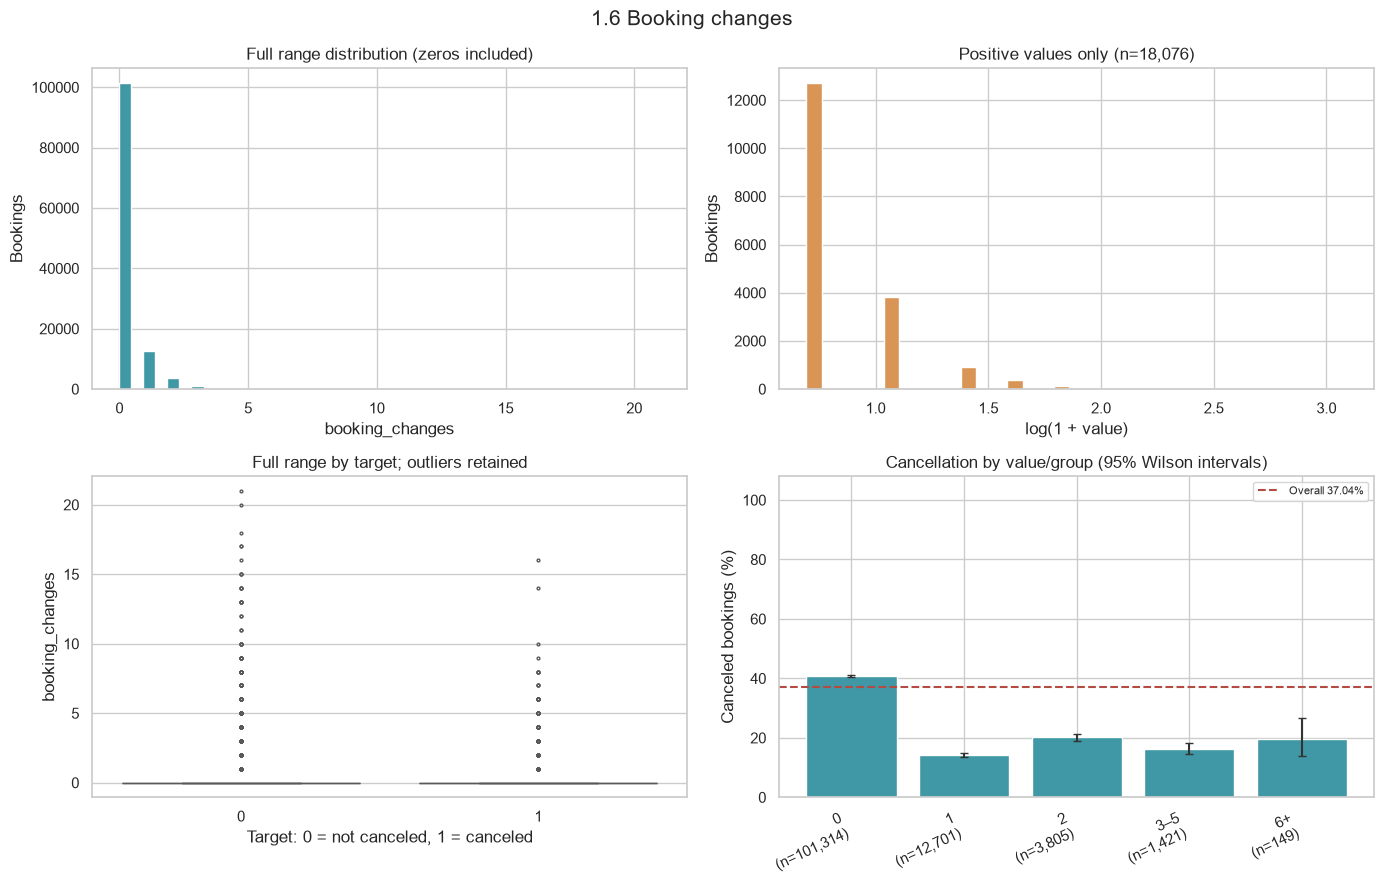

In [7]:
m1_analyse('booking_changes', '1.6 Booking changes')

**Finding:** 84.86% have no changes; the maximum is 21. Cancellation is 15.67% with changes and 40.85% without changes. Changes may accumulate after booking, so their availability at prediction time must be checked.

### 1.7 Days in waiting list

Separate never-waitlisted bookings from positive waiting durations. The positive-only view is necessary because zeros dominate the distribution.

,days_in_waiting_list,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115692,41865,96.903,36.187,35.910,36.464
1,1,12,3,0.010,25.000,8.894,53.231
2,2,5,1,0.004,20.000,3.622,62.447
3,3,59,59,0.049,100.000,93.887,100.000
4,4,25,8,0.021,32.000,17.205,51.590
...,...,...,...,...,...,...,...
123,236,35,6,0.029,17.143,8.103,32.683
124,259,10,0,0.008,0.000,-0.000,27.754
125,330,15,1,0.013,6.667,1.187,29.817
126,379,15,9,0.013,60.000,35.746,80.176


,days_in_waiting_list_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,115692,41865,96.903,36.187,35.910,36.464
1,1–7,129,79,0.108,61.240,52.624,69.207
2,8–30,463,368,0.388,79.482,75.568,82.910
3,31–90,2138,1395,1.791,65.248,63.204,67.237
4,91+,968,517,0.811,53.409,50.259,56.532


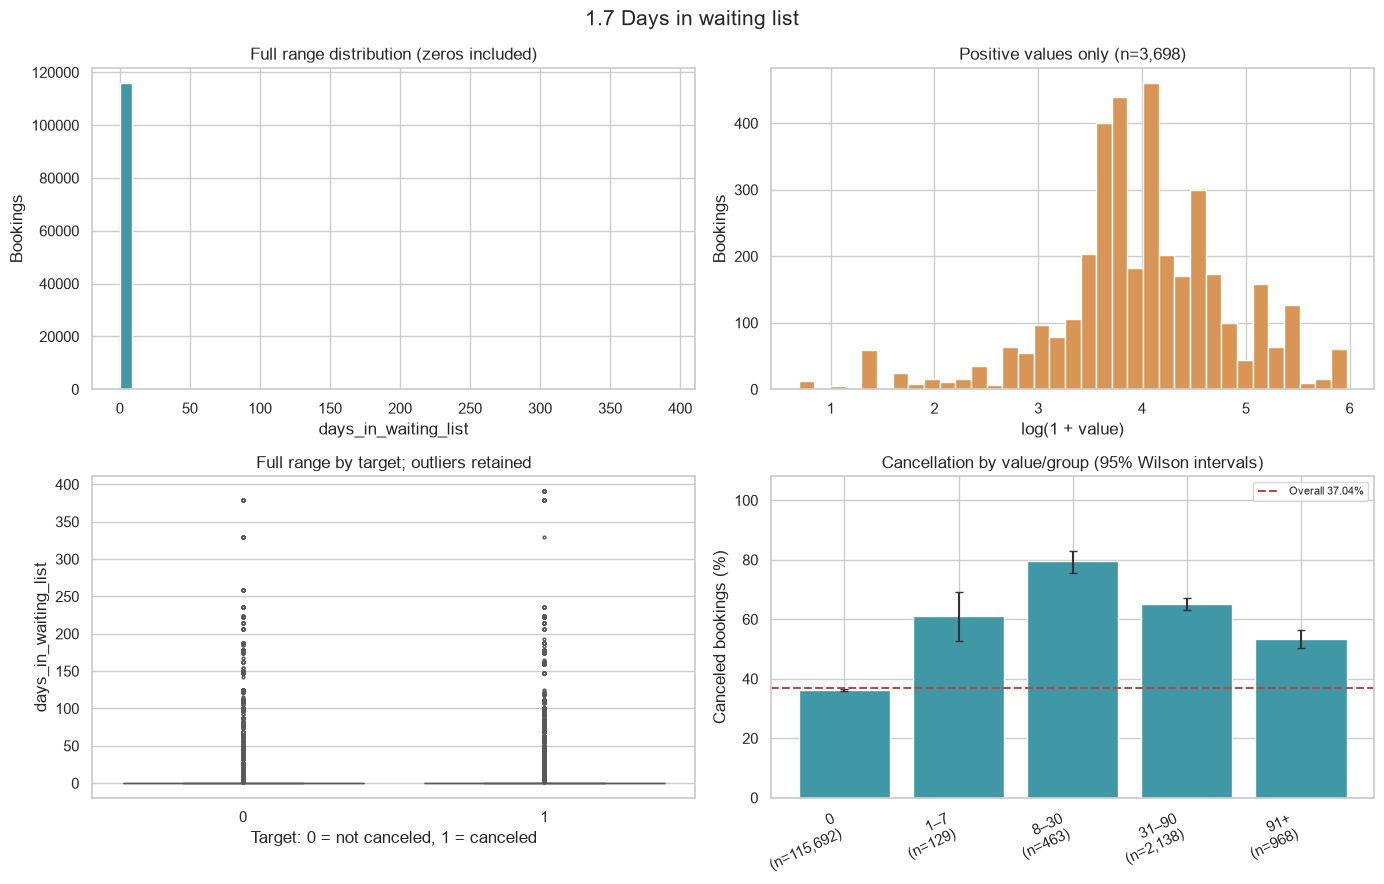

In [8]:
m1_analyse('days_in_waiting_list', '1.7 Days in waiting list')

**Finding:** 96.90% have zero waiting days. Cancellation is 63.79% for waitlisted bookings and 36.19% for those with zero waiting days. The maximum wait is 391 days; no waiting duration exceeds lead time.

### 1.8 Special requests

Use discrete request counts. Always read the rate with its denominator, especially for four and five requests.

,total_of_special_requests,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,70318,33556,58.898,47.720,47.351,48.090
1,1,33226,7318,27.830,22.025,21.583,22.474
2,2,12969,2866,10.863,22.099,21.393,22.821
3,3,2497,446,2.091,17.861,16.409,19.413
4,4,340,36,0.285,10.588,7.747,14.311
5,5,40,2,0.034,5.000,1.382,16.504


,total_of_special_requests,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,0,70318,33556,58.898,47.720,47.351,48.090
1,1,33226,7318,27.830,22.025,21.583,22.474
2,2,12969,2866,10.863,22.099,21.393,22.821
3,3,2497,446,2.091,17.861,16.409,19.413
4,4,340,36,0.285,10.588,7.747,14.311
5,5,40,2,0.034,5.000,1.382,16.504


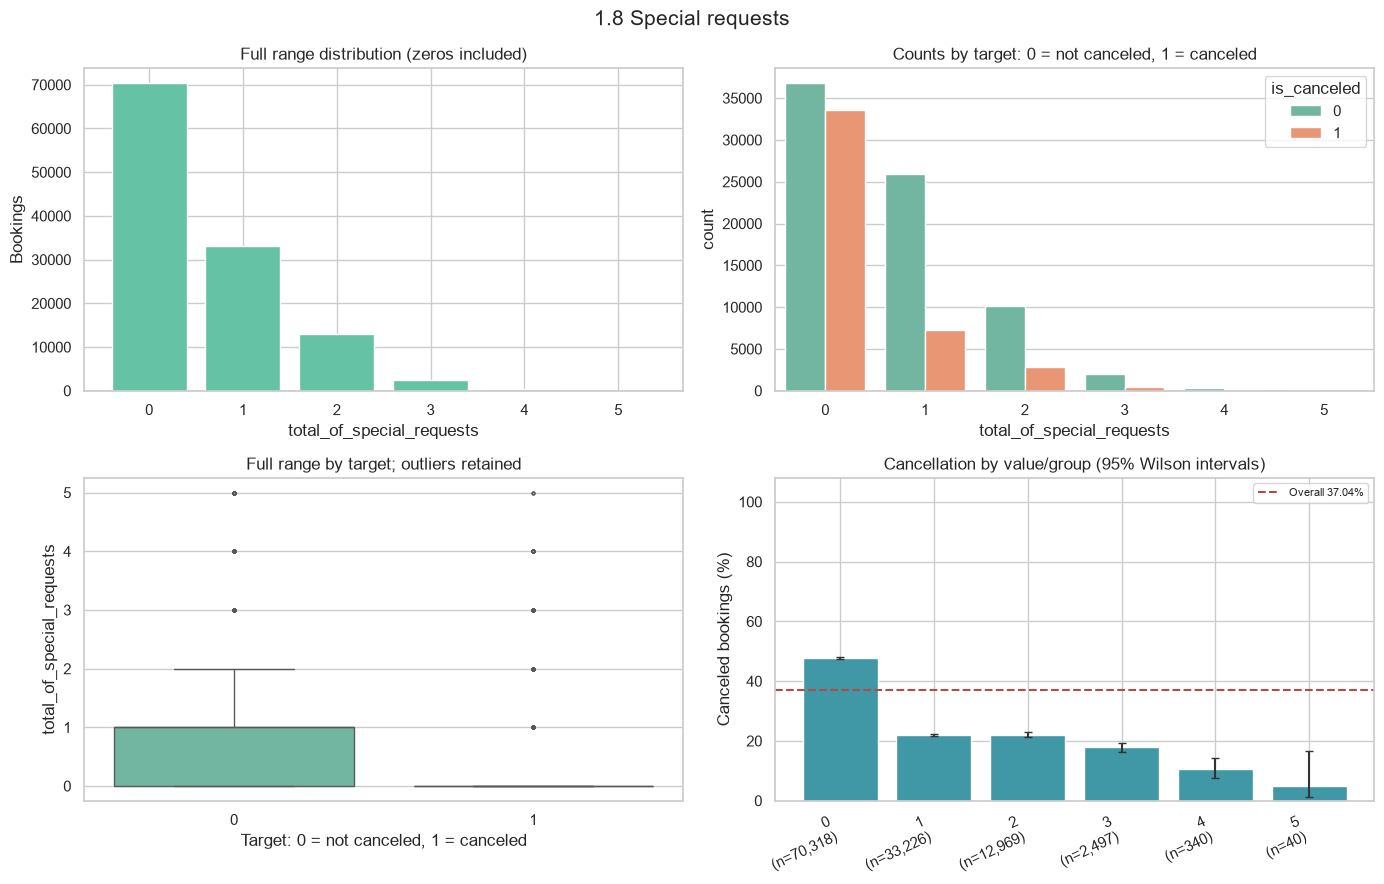

In [9]:
m1_analyse('total_of_special_requests', '1.8 Special requests')

**Finding:** Cancellation is 47.72% without requests and 21.74% with at least one request. Counts range from 0 to 5; only 40 bookings have five requests, so the 5.00% cancellation estimate for that group needs caution.

### 1.9 Customer type

Compare all observed customer categories without assigning them an artificial numerical order.

,customer_type,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,Contract,4076,1262,3.414,30.962,29.561,32.398
1,Group,577,59,0.483,10.225,8.010,12.966
2,Transient,89613,36514,75.059,40.746,40.425,41.068
3,Transient-Party,25124,6389,21.044,25.430,24.895,25.972


,customer_type,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,Contract,4076,1262,3.414,30.962,29.561,32.398
1,Group,577,59,0.483,10.225,8.010,12.966
2,Transient,89613,36514,75.059,40.746,40.425,41.068
3,Transient-Party,25124,6389,21.044,25.430,24.895,25.972


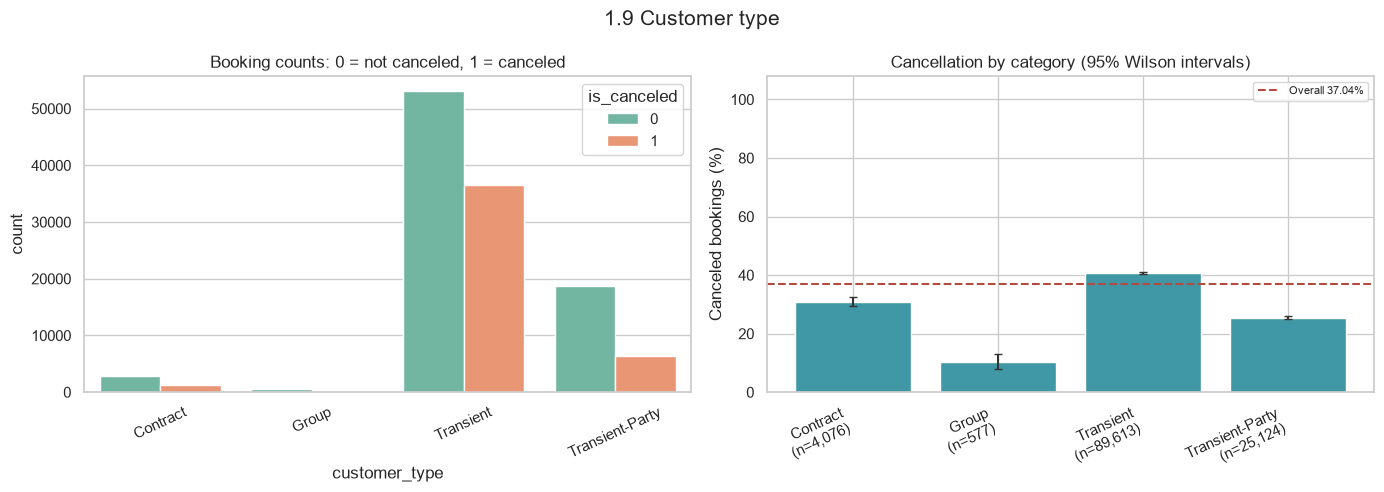

In [10]:
m1_analyse('customer_type', '1.9 Customer type')

**Finding:** Transient bookings have the highest pooled cancellation rate (40.75%), followed by Contract (30.96%), Transient-Party (25.43%), and Group (10.23%). Contract rates differ strongly by hotel: 48.04% at City Hotel and 8.84% at Resort Hotel.

### 1.10 Related target comparisons and hotel context

Compare the presence of each behavior, inspect recorded history alongside the repeated-guest flag,
and stratify each variable by hotel. These checks expose overlap and hotel composition; they do not
fully adjust for lead time, customer type, deposit policy, or other confounders.


In [11]:
m1_presence = []
for c in ['previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes',
          'days_in_waiting_list', 'total_of_special_requests']:
    temporary = m1.assign(presence=np.where(m1[c].gt(0), 'Positive', 'Zero'))
    rates = m1_rates(temporary, 'presence')
    rates.insert(0, 'variable', c)
    m1_presence.append(rates)
m1_presence = pd.concat(m1_presence, ignore_index=True)
m1_show(m1_presence, 'zero_vs_positive_target')
m1['has_recorded_history'] = (m1.previous_cancellations + m1.previous_bookings_not_canceled).gt(0).astype(int)
m1_history = m1.groupby(['is_repeated_guest', 'has_recorded_history'], observed=True).is_canceled.agg(
    bookings='size', canceled='sum', cancellation_rate='mean').reset_index()
m1_history['cancellation_rate_pct'] = m1_history.pop('cancellation_rate') * 100
m1_show(m1_history, 'repeated_guest_history_crosscheck')
m1_strata = []
for c, group in m1_group_columns.items():
    for hotel, part in m1.groupby('hotel'):
        rates = m1_rates(part, group).rename(columns={group: 'value_or_group'})
        rates['value_or_group'] = rates['value_or_group'].astype(str)
        rates.insert(0, 'hotel', hotel)
        rates.insert(0, 'variable', c)
        m1_strata.append(rates)
m1_show(pd.concat(m1_strata, ignore_index=True), 'target_comparisons_by_hotel')


,variable,presence,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,previous_cancellations,Positive,6484,5942,5.431,91.641,90.942,92.290
1,previous_cancellations,Zero,112906,38282,94.569,33.906,33.631,34.183
2,previous_bookings_not_canceled,Positive,3620,200,3.032,5.525,4.827,6.317
3,previous_bookings_not_canceled,Zero,115770,44024,96.968,38.027,37.748,38.307
4,booking_changes,Positive,18076,2833,15.140,15.673,15.150,16.210
5,booking_changes,Zero,101314,41391,84.860,40.854,40.552,41.157
6,days_in_waiting_list,Positive,3698,2359,3.097,63.791,62.229,65.325
7,days_in_waiting_list,Zero,115692,41865,96.903,36.187,35.910,36.464
8,total_of_special_requests,Positive,49072,10668,41.102,21.739,21.377,22.107
9,total_of_special_requests,Zero,70318,33556,58.898,47.720,47.351,48.090


,is_repeated_guest,has_recorded_history,bookings,canceled,cancellation_rate_pct
0,0,0,109343,38180,34.918
1,0,1,6237,5492,88.055
2,1,0,590,32,5.424
3,1,1,3220,520,16.149


,variable,hotel,value_or_group,bookings,canceled,share_pct,cancellation_rate_pct,ci95_low_pct,ci95_high_pct
0,lead_time,City Hotel,0,3109,273,3.919,8.781,7.836,9.827
1,lead_time,City Hotel,1–7,7699,1046,9.705,13.586,12.839,14.370
2,lead_time,City Hotel,8–30,12554,3880,15.825,30.906,30.104,31.721
3,lead_time,City Hotel,31–90,20797,8300,26.216,39.910,39.246,40.577
4,lead_time,City Hotel,91–180,18223,8746,22.971,47.994,47.269,48.720
...,...,...,...,...,...,...,...,...,...
73,customer_type,City Hotel,Transient-Party,17333,4870,21.849,28.097,27.432,28.771
74,customer_type,Resort Hotel,Contract,1776,157,4.433,8.840,7.607,10.251
75,customer_type,Resort Hotel,Group,284,30,0.709,10.563,7.500,14.679
76,customer_type,Resort Hotel,Transient,30209,9416,75.409,31.170,30.650,31.694


### 1.11 Outliers and unusual observations

Tukey fences use Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. When Q1 = Q3 = 0, every positive
value is flagged: this is a limitation of the rule for zero-heavy counts, not evidence that those rows
are erroneous. Domain-review thresholds below are explicitly exploratory. Inspect the largest
observations using only relevant booking fields; row indices identify source rows, not customers.


In [12]:
m1_outliers = []
for c in m1_numeric:
    q1, q3 = m1[c].quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    flag = m1[c].lt(low) | m1[c].gt(high)
    m1_outliers.append({'variable': c, 'q1': q1, 'q3': q3, 'iqr': iqr,
                        'lower_fence': low, 'upper_fence': high, 'flagged_rows': flag.sum(),
                        'flagged_pct': flag.mean()*100, 'zero_iqr': iqr == 0,
                        'above_p99_rows': m1[c].gt(m1[c].quantile(.99)).sum(),
                        'maximum': m1[c].max()})
m1_show(pd.DataFrame(m1_outliers), 'iqr_outlier_review')
m1_checks = {
    'Lead time > 365 days': m1.lead_time.gt(365),
    'Previous cancellations > 5': m1.previous_cancellations.gt(5),
    'Previous non-canceled bookings > 20': m1.previous_bookings_not_canceled.gt(20),
    'Booking changes > 5': m1.booking_changes.gt(5),
    'Waiting time > 90 days': m1.days_in_waiting_list.gt(90),
    'Special requests >= 4 (rare, not invalid)': m1.total_of_special_requests.ge(4),
    'Waiting days > lead time (definition review)': m1.days_in_waiting_list.gt(m1.lead_time),
    'Repeated flag = 0 but recorded history exists': m1.is_repeated_guest.eq(0) & m1.has_recorded_history.eq(1),
    'Repeated flag = 1 but no recorded history': m1.is_repeated_guest.eq(1) & m1.has_recorded_history.eq(0),
    'Invalid repeated guest flag': ~m1.is_repeated_guest.isin([0, 1]),
    'Missing or blank customer type': m1.customer_type.isna() | m1.customer_type.str.strip().eq(''),
}
m1_unusual = pd.DataFrame([{'check': label, 'bookings': int(mask.sum()),
    'share_pct': mask.mean()*100,
    'cancellation_rate_pct': m1.loc[mask, 'is_canceled'].mean()*100}
    for label, mask in m1_checks.items()])
m1_show(m1_unusual, 'unusual_observations')
m1_extremes = []
for c in m1_numeric:
    sample = m1.nlargest(3, c)[m1_columns + ['hotel', 'is_canceled']].copy()
    sample.insert(0, 'source_row_index', sample.index)
    sample.insert(0, 'reviewed_variable', c)
    m1_extremes.append(sample)
m1_show(pd.concat(m1_extremes, ignore_index=True), 'largest_observations')


,variable,q1,q3,iqr,lower_fence,upper_fence,flagged_rows,flagged_pct,zero_iqr,above_p99_rows,maximum
0,lead_time,18.0,160.0,142.0,-195.0,373.0,3005,2.517,False,1178,737
1,previous_cancellations,0.0,0.0,0.0,0.0,0.0,6484,5.431,True,433,26
2,previous_bookings_not_canceled,0.0,0.0,0.0,0.0,0.0,3620,3.032,True,1165,72
3,booking_changes,0.0,0.0,0.0,0.0,0.0,18076,15.140,True,643,21
4,days_in_waiting_list,0.0,0.0,0.0,0.0,0.0,3698,3.097,True,1178,391
5,total_of_special_requests,0.0,1.0,1.0,-1.5,2.5,2877,2.410,False,380,5


,check,bookings,share_pct,cancellation_rate_pct
0,Lead time > 365 days,3148,2.637,67.662
1,Previous cancellations > 5,202,0.169,79.703
2,Previous non-canceled bookings > 20,135,0.113,11.111
3,Booking changes > 5,149,0.125,19.463
4,Waiting time > 90 days,968,0.811,53.409
5,"Special requests >= 4 (rare, not invalid)",380,0.318,10.000
6,Waiting days > lead time (definition review),0,0.000,NaN
7,Repeated flag = 0 but recorded history exists,6237,5.224,88.055
8,Repeated flag = 1 but no recorded history,590,0.494,5.424
9,Invalid repeated guest flag,0,0.000,NaN


,reviewed_variable,source_row_index,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,total_of_special_requests,is_repeated_guest,customer_type,hotel,is_canceled
0,lead_time,1,737,0,0,4,0,0,0,Transient,Resort Hotel,0
1,lead_time,4182,709,0,0,2,0,0,0,Transient,Resort Hotel,0
2,lead_time,65231,629,0,0,0,0,0,0,Transient,City Hotel,1
3,previous_cancellations,14779,275,26,0,0,0,0,0,Transient,Resort Hotel,1
4,previous_cancellations,14780,275,26,0,0,0,0,0,Transient,Resort Hotel,1
5,previous_cancellations,14781,275,26,0,0,0,0,0,Transient,Resort Hotel,1
6,previous_bookings_not_canceled,76731,0,6,72,0,0,2,1,Transient,City Hotel,0
7,previous_bookings_not_canceled,76730,4,6,71,1,0,2,1,Transient,City Hotel,0
8,previous_bookings_not_canceled,76729,4,6,70,0,0,1,1,Transient,City Hotel,0
9,booking_changes,88017,16,0,0,21,0,0,0,Transient-Party,City Hotel,0


### 1.12 Preprocessing implications

- No missing values were found in the eight assigned variables. Keep genuine zeros.
- Consider log1p or robust scaling for skewed numerical features; validate extreme observations before capping or removal.
- Previous cancellations, previous bookings not canceled, booking changes, and waiting days have zero IQR. An IQR rule would flag every positive value, so it should not be used for automatic removal.
- Keep repeated guest as binary and one-hot encode customer type. Consider presence indicators alongside history counts, changes, waiting days, and special requests.
- Review the 6,237 bookings marked non-repeated despite recorded history and the 590 marked repeated without recorded history; do not automatically recode them.
- Use only information available at prediction time, especially booking changes, waiting duration, and requests. Fit preprocessing on training data only.
- These are descriptive associations, not evidence that requests or booking changes cause fewer cancellations.


## Member 2 - Stay & Reservation Analysis

This section analyses stay and reservation attributes assigned to Member 2:

- Hotel type
- Arrival period
- Weekend-night stays
- Week-night stays
- Adults, children, babies
- Meal
- Reserved room type
- Parking requirements
- Related target comparisons
- Outliers or unusual observations
- Feature-engineering opportunities such as `total_stay` and `total_guests`

### 2.1 Hotel Type Distribution and Cancellation Rate

In [7]:
hotel_counts = df['hotel'].value_counts().reset_index()
hotel_counts.columns = ['hotel', 'count']
hotel_counts['percentage'] = (hotel_counts['count'] / len(df) * 100).round(2)
hotel_counts

,hotel,count,percentage
0,City Hotel,79330,66.45
1,Resort Hotel,40060,33.55


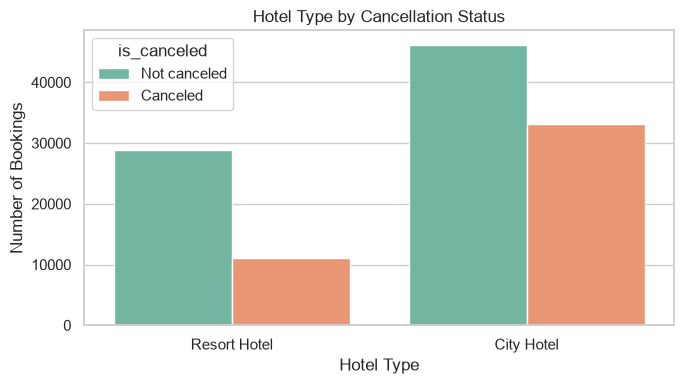

Saved figure: Figures\stay_reservation\hotel_type_by_cancellation.png


In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='hotel', hue='is_canceled')
plt.title('Hotel Type by Cancellation Status')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('hotel_type_by_cancellation.png')

In [9]:
hotel_cancel_rate = cancellation_rate_table(df, 'hotel')
hotel_cancel_rate

,hotel,total_bookings,canceled_bookings,cancellation_rate
0,City Hotel,79330,33102,41.73
1,Resort Hotel,40060,11122,27.76


In [10]:
highest_hotel = hotel_cancel_rate.iloc[0]
lowest_hotel = hotel_cancel_rate.iloc[-1]
rate_gap = highest_hotel['cancellation_rate'] - lowest_hotel['cancellation_rate']
print(f"Observed result: {highest_hotel['hotel']} has the higher cancellation rate "
      f"({highest_hotel['cancellation_rate']:.2f}%) compared with {lowest_hotel['hotel']} "
      f"({lowest_hotel['cancellation_rate']:.2f}%).")
print(f"Difference: approximately {rate_gap:.2f} percentage points.")

Observed result: City Hotel has the higher cancellation rate (41.73%) compared with Resort Hotel (27.76%).
Difference: approximately 13.97 percentage points.


**Finding:** The hotel-type comparison should be interpreted using the observed cancellation-rate table above. The hotel category with the higher cancellation rate may capture different booking behaviour, customer segments, or reservation conditions. This variable should be retained as a categorical predictor and encoded during preprocessing.

### 2.2 Arrival Period Analysis

This section focuses on arrival month and arrival year because they are the most meaningful period-level variables for identifying broad seasonal and yearly cancellation patterns. Week number and day of month are not visualized here to avoid adding less interpretable plots without a clear analytical purpose.

In [11]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
arrival_month_summary = cancellation_rate_table(df, 'arrival_date_month')
arrival_month_summary['arrival_date_month'] = pd.Categorical(arrival_month_summary['arrival_date_month'], categories=month_order, ordered=True)
arrival_month_summary.sort_values('arrival_date_month')

,arrival_date_month,total_bookings,canceled_bookings,cancellation_rate
4,January,5929,1807,30.48
3,February,8068,2696,33.42
7,March,9794,3149,32.15
0,April,11089,4524,40.80
8,May,11791,4677,39.67
6,June,10939,4535,41.46
5,July,12661,4742,37.45
1,August,13877,5239,37.75
11,September,10508,4116,39.17
10,October,11160,4246,38.05


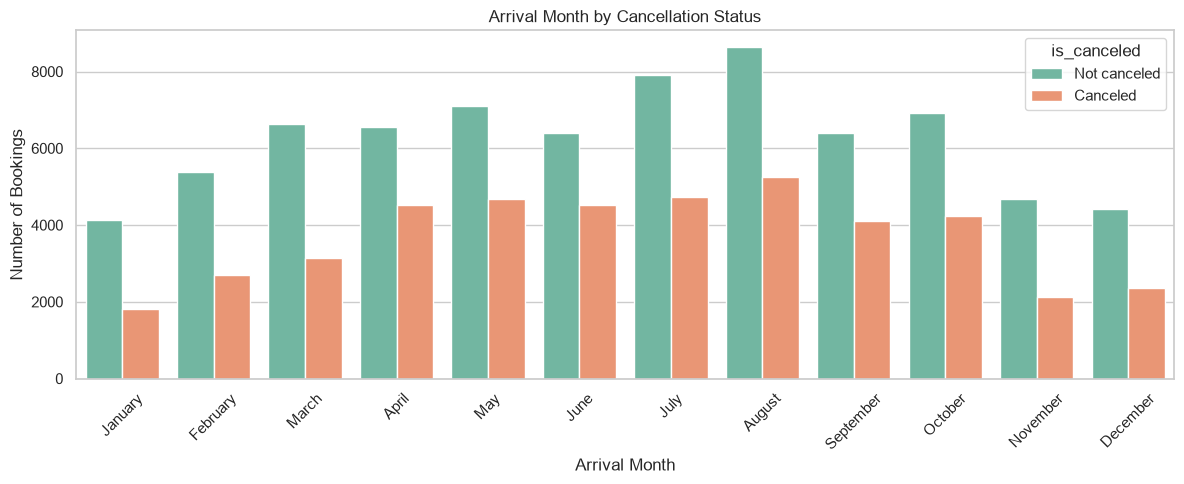

Saved figure: Figures\stay_reservation\arrival_month_by_cancellation.png


In [12]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='arrival_date_month', hue='is_canceled', order=month_order)
plt.title('Arrival Month by Cancellation Status')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('arrival_month_by_cancellation.png')

In [13]:
arrival_year_summary = cancellation_rate_table(df, 'arrival_date_year')
arrival_year_summary

,arrival_date_year,total_bookings,canceled_bookings,cancellation_rate
2,2017,40687,15745,38.70
0,2015,21996,8142,37.02
1,2016,56707,20337,35.86


In [14]:
arrival_month_rates = arrival_month_summary.sort_values('cancellation_rate', ascending=False)
arrival_year_rates = arrival_year_summary.sort_values('cancellation_rate', ascending=False)
print(f"Highest cancellation month: {arrival_month_rates.iloc[0]['arrival_date_month']} "
      f"({arrival_month_rates.iloc[0]['cancellation_rate']:.2f}%).")
print(f"Lowest cancellation month: {arrival_month_rates.iloc[-1]['arrival_date_month']} "
      f"({arrival_month_rates.iloc[-1]['cancellation_rate']:.2f}%).")
print(f"Highest cancellation year: {arrival_year_rates.iloc[0]['arrival_date_year']} "
      f"({arrival_year_rates.iloc[0]['cancellation_rate']:.2f}%).")

Highest cancellation month: June (41.46%).
Lowest cancellation month: January (30.48%).
Highest cancellation year: 2017.0 (38.70%).


**Finding:** Arrival month and year show period-level differences in cancellation rates. These observed differences suggest that arrival timing may contain useful seasonal or yearly information. During preprocessing/feature engineering, month and year should be handled as time-related features rather than ignored.

### 2.3 Stay Duration Analysis

This section examines weekend-night stays and week-night stays. It also proposes `total_stay` as a future engineered feature.

In [15]:
stay_columns = ['stays_in_weekend_nights', 'stays_in_week_nights']
df[stay_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stays_in_weekend_nights,119390.0,0.93,1.00,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.0,1.0,2.0,3.0,50.0


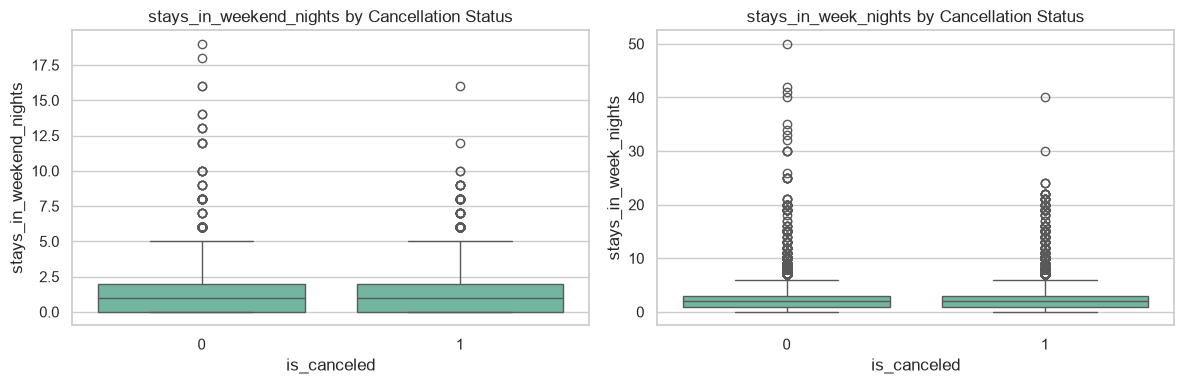

Saved figure: Figures\stay_reservation\stay_nights_boxplots.png


In [16]:
plt.figure(figsize=(12, 4))
for i, column in enumerate(stay_columns, start=1):
    plt.subplot(1, 2, i)
    sns.boxplot(data=df, x='is_canceled', y=column)
    plt.title(f'{column} by Cancellation Status')
    plt.xlabel('is_canceled')
    plt.ylabel(column)
save_current_figure('stay_nights_boxplots.png')

In [17]:
df_member2 = df.copy()
df_member2['total_stay'] = df_member2['stays_in_weekend_nights'] + df_member2['stays_in_week_nights']
total_stay_summary = df_member2['total_stay'].describe().to_frame('total_stay').T.round(2)
zero_night_count = int((df_member2['total_stay'] == 0).sum())
total_stay_summary['zero_night_bookings'] = zero_night_count
total_stay_summary

,count,mean,std,min,25%,50%,75%,max,zero_night_bookings
total_stay,119390.0,3.43,2.56,0.0,2.0,3.0,4.0,69.0,715


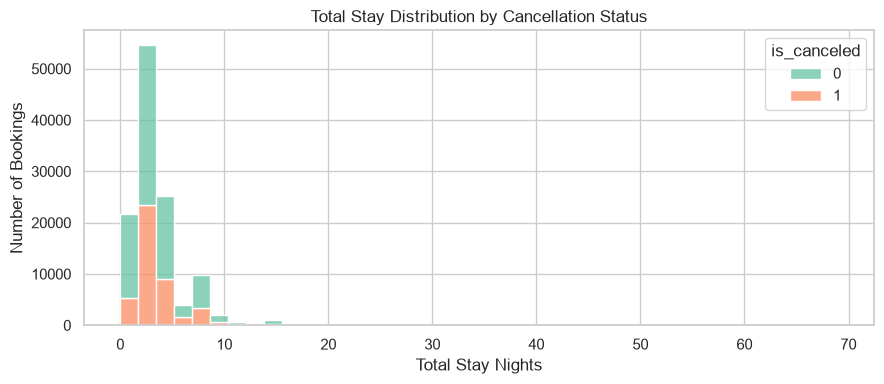

Saved figure: Figures\stay_reservation\total_stay_distribution.png


In [18]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df_member2, x='total_stay', hue='is_canceled', bins=40, kde=False, multiple='stack')
plt.title('Total Stay Distribution by Cancellation Status')
plt.xlabel('Total Stay Nights')
plt.ylabel('Number of Bookings')
save_current_figure('total_stay_distribution.png')

In [19]:
df_member2['stay_length_group'] = pd.cut(
    df_member2['total_stay'],
    bins=[-1, 0, 2, 7, np.inf],
    labels=['Zero-night stay', 'Short stay (1-2 nights)', 'Medium stay (3-7 nights)', 'Long stay (8+ nights)']
)
stay_length_cancel_rate = cancellation_rate_table(df_member2, 'stay_length_group')
stay_length_cancel_rate.sort_values('stay_length_group')

,stay_length_group,total_bookings,canceled_bookings,cancellation_rate
0,Zero-night stay,715,35,4.90
1,Short stay (1-2 nights),48663,17434,35.83
2,Medium stay (3-7 nights),64755,24876,38.42
3,Long stay (8+ nights),5257,1879,35.74


In [20]:
stay_rates = stay_length_cancel_rate.sort_values('cancellation_rate', ascending=False)
print(f"Highest cancellation stay group: {stay_rates.iloc[0]['stay_length_group']} "
      f"({stay_rates.iloc[0]['cancellation_rate']:.2f}%).")
print(f"Lowest cancellation stay group: {stay_rates.iloc[-1]['stay_length_group']} "
      f"({stay_rates.iloc[-1]['cancellation_rate']:.2f}%).")

Highest cancellation stay group: Medium stay (3-7 nights) (38.42%).
Lowest cancellation stay group: Zero-night stay (4.90%).


**Finding:** The binned stay-length comparison provides a clearer target comparison for `total_stay`. If cancellation rates differ across stay-length groups, `total_stay` may be useful as an engineered feature. Zero-night and very long-stay records should still be investigated during preprocessing rather than removed during EDA.

### 2.4 Guest Composition Analysis

This section analyses adults, children, and babies. It also proposes `total_guests` as a possible engineered feature.

In [21]:
guest_columns = ['adults', 'children', 'babies']
df[guest_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
adults,119390.0,1.86,0.58,0.0,2.0,2.0,2.0,55.0
children,119386.0,0.10,0.40,0.0,0.0,0.0,0.0,10.0
babies,119390.0,0.01,0.10,0.0,0.0,0.0,0.0,10.0


In [22]:
# EDA-only temporary treatment: children has 4 missing values.
# For exploratory calculation of total_guests, missing children values are temporarily treated as 0.
# Final missing-value treatment must be justified and performed during preprocessing.
df_member2['children'] = df_member2['children'].fillna(0)
df_member2['total_guests'] = df_member2['adults'] + df_member2['children'] + df_member2['babies']
guest_summary = df_member2[['adults', 'children', 'babies', 'total_guests']].describe().T.round(2)
guest_summary['zero_guest_bookings'] = [
    int((df_member2['adults'] == 0).sum()),
    int((df_member2['children'] == 0).sum()),
    int((df_member2['babies'] == 0).sum()),
    int((df_member2['total_guests'] == 0).sum())
]
guest_summary

,count,mean,std,min,25%,50%,75%,max,zero_guest_bookings
adults,119390.0,1.86,0.58,0.0,2.0,2.0,2.0,55.0,403
children,119390.0,0.10,0.40,0.0,0.0,0.0,0.0,10.0,110800
babies,119390.0,0.01,0.10,0.0,0.0,0.0,0.0,10.0,118473
total_guests,119390.0,1.97,0.72,0.0,2.0,2.0,2.0,55.0,180


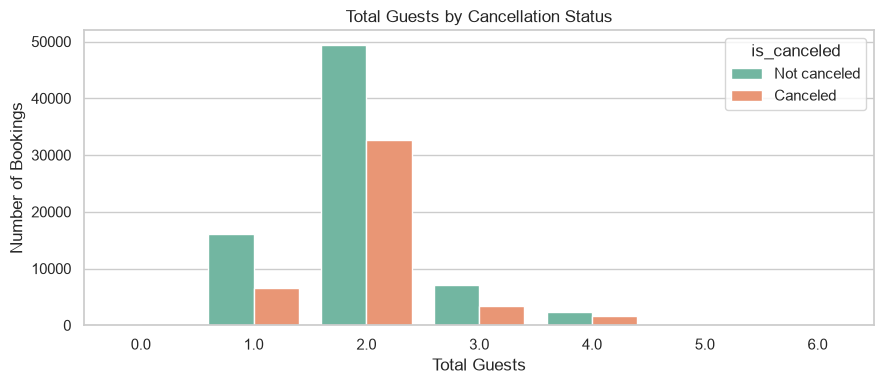

Saved figure: Figures\stay_reservation\total_guests_by_cancellation.png


In [23]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df_member2[df_member2['total_guests'] <= 6], x='total_guests', hue='is_canceled')
plt.title('Total Guests by Cancellation Status')
plt.xlabel('Total Guests')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('total_guests_by_cancellation.png')

In [24]:
df_member2['has_children'] = np.where(df_member2['children'] > 0, 'Has children', 'No children')
df_member2['has_babies'] = np.where(df_member2['babies'] > 0, 'Has babies', 'No babies')
children_babies_cancel_rate = pd.concat(
    [
        cancellation_rate_table(df_member2, 'has_children').assign(feature='children_presence'),
        cancellation_rate_table(df_member2, 'has_babies').assign(feature='babies_presence'),
    ],
    ignore_index=True
)
children_babies_cancel_rate

,has_children,total_bookings,canceled_bookings,cancellation_rate,feature,has_babies
0,No children,110800,41098,37.09,children_presence,NaN
1,Has children,8590,3126,36.39,children_presence,NaN
2,NaN,118473,44057,37.19,babies_presence,No babies
3,NaN,917,167,18.21,babies_presence,Has babies


In [25]:
children_rates = cancellation_rate_table(df_member2, 'has_children')
babies_rates = cancellation_rate_table(df_member2, 'has_babies')
print('Children presence cancellation rates:')
print(children_rates[['has_children', 'cancellation_rate']].to_string(index=False))
print('\nBabies presence cancellation rates:')
print(babies_rates[['has_babies', 'cancellation_rate']].to_string(index=False))

Children presence cancellation rates:
has_children  cancellation_rate
 No children              37.09
Has children              36.39

Babies presence cancellation rates:
has_babies  cancellation_rate
 No babies              37.19
Has babies              18.21


**Finding:** `total_guests` is a useful feature-engineering opportunity, but individual guest-composition indicators are also informative. Comparing bookings with and without children/babies gives a clearer view of how family-related guest composition relates to cancellation. Records with zero total guests should be treated as unusual and investigated during preprocessing.

### 2.5 Meal Type Analysis

In [26]:
df['meal'].value_counts(dropna=False).to_frame('count')

,count
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798


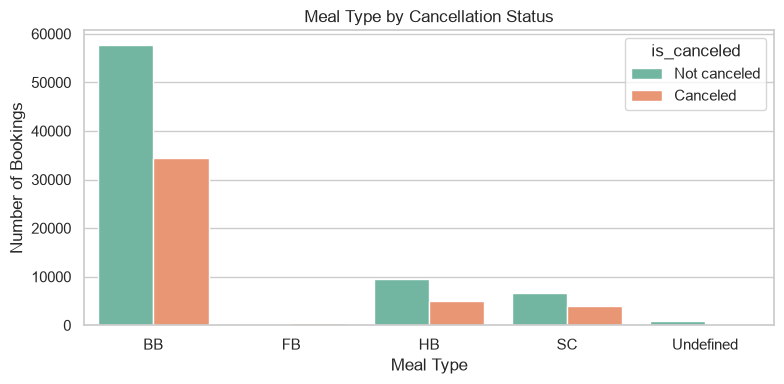

Saved figure: Figures\stay_reservation\meal_type_by_cancellation.png


In [27]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='meal', hue='is_canceled')
plt.title('Meal Type by Cancellation Status')
plt.xlabel('Meal Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('meal_type_by_cancellation.png')

In [28]:
cancellation_rate_table(df, 'meal')

,meal,total_bookings,canceled_bookings,cancellation_rate
1,FB,798,478,59.90
0,BB,92310,34510,37.38
3,SC,10650,3966,37.24
2,HB,14463,4984,34.46
4,Undefined,1169,286,24.47


**Finding:** Meal is a categorical feature and should be encoded during preprocessing. Undefined or rare categories should be reviewed before encoding.

### 2.6 Reserved Room Type Analysis

In [29]:
df['reserved_room_type'].value_counts(dropna=False).to_frame('count')

,count
reserved_room_type,
A,85994
D,19201
E,6535
F,2897
G,2094
B,1118
C,932
H,601
P,12


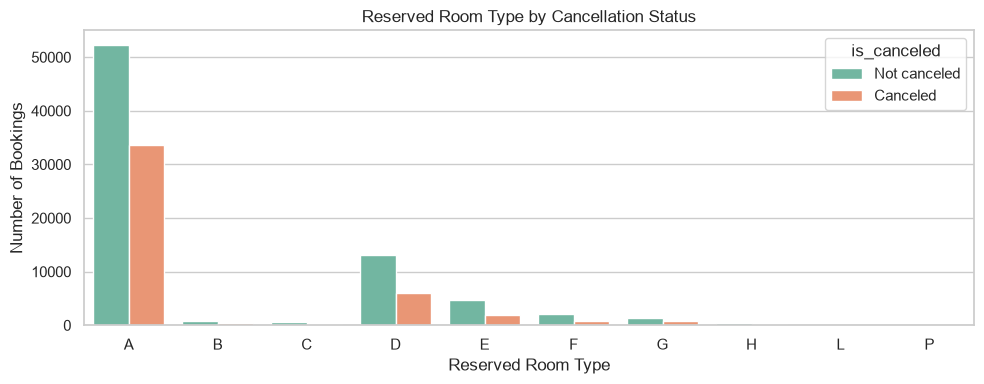

Saved figure: Figures\stay_reservation\reserved_room_type_by_cancellation.png


In [30]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='reserved_room_type', hue='is_canceled', order=sorted(df['reserved_room_type'].unique()))
plt.title('Reserved Room Type by Cancellation Status')
plt.xlabel('Reserved Room Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('reserved_room_type_by_cancellation.png')

In [31]:
cancellation_rate_table(df, 'reserved_room_type')

,reserved_room_type,total_bookings,canceled_bookings,cancellation_rate
9,P,12,12,100.00
7,H,601,245,40.77
0,A,85994,33630,39.11
6,G,2094,763,36.44
8,L,6,2,33.33
2,C,932,308,33.05
1,B,1118,368,32.92
3,D,19201,6102,31.78
5,F,2897,880,30.38
4,E,6535,1914,29.29


**Finding:** Reserved room type may reflect customer preference and booking conditions. It should be retained as a categorical feature, while rare room categories may require careful encoding.

### 2.7 Parking Requirement Analysis

In [32]:
df['required_car_parking_spaces'].value_counts(dropna=False).sort_index().to_frame('count')

,count
required_car_parking_spaces,
0,111974
1,7383
2,28
3,3
8,2


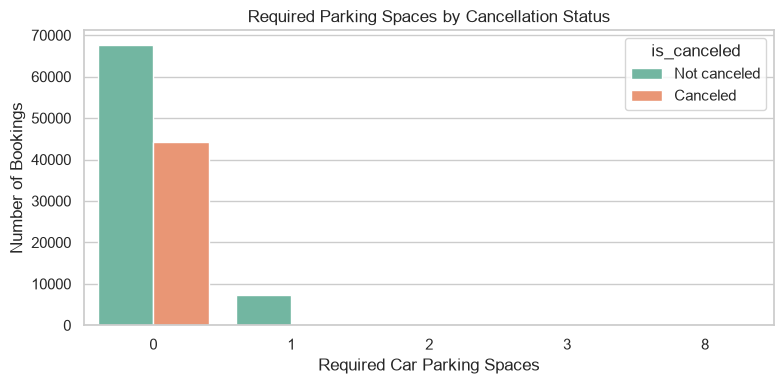

Saved figure: Figures\stay_reservation\parking_spaces_by_cancellation.png


In [33]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='required_car_parking_spaces', hue='is_canceled')
plt.title('Required Parking Spaces by Cancellation Status')
plt.xlabel('Required Car Parking Spaces')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])
save_current_figure('parking_spaces_by_cancellation.png')

In [34]:
parking_cancel_rate = cancellation_rate_table(df, 'required_car_parking_spaces')
parking_cancel_rate

,required_car_parking_spaces,total_bookings,canceled_bookings,cancellation_rate
0,0,111974,44224,39.49
1,1,7383,0,0.00
2,2,28,0,0.00
3,3,3,0,0.00
4,8,2,0,0.00


In [35]:
no_parking_rate = parking_cancel_rate.loc[parking_cancel_rate['required_car_parking_spaces'].eq(0), 'cancellation_rate'].iloc[0]
parking_requested = df.assign(parking_requested=np.where(df['required_car_parking_spaces'] > 0, 'Parking requested', 'No parking requested'))
parking_request_rate = cancellation_rate_table(parking_requested, 'parking_requested')
print(parking_request_rate.to_string(index=False))
print(f"Cancellation rate for zero parking spaces: {no_parking_rate:.2f}%")

   parking_requested  total_bookings  canceled_bookings  cancellation_rate
No parking requested          111974              44224              39.49
   Parking requested            7416                  0               0.00
Cancellation rate for zero parking spaces: 39.49%


**Finding:** Parking should be interpreted from the observed cancellation-rate table above. If bookings with requested parking show a lower cancellation rate than bookings with no parking request, this supports the idea that parking requests may indicate stronger booking intention. The variable is discrete numerical and may be useful without complex transformation, while rare high values should be reviewed.

### 2.8 Member 2 Outlier and Unusual Observation Summary

In [36]:
member2_unusual = pd.DataFrame([
    {'check': 'Zero total stay nights', 'count': int((df_member2['total_stay'] == 0).sum())},
    {'check': 'Very long stays above 30 nights', 'count': int((df_member2['total_stay'] > 30).sum())},
    {'check': 'Missing children values', 'count': int(df['children'].isna().sum())},
    {'check': 'Zero total guests', 'count': int((df_member2['total_guests'] == 0).sum())},
    {'check': 'Bookings with more than 6 guests', 'count': int((df_member2['total_guests'] > 6).sum())},
    {'check': 'Undefined meal values', 'count': int((df['meal'] == 'Undefined').sum())},
    {'check': 'Parking spaces greater than 2', 'count': int((df['required_car_parking_spaces'] > 2).sum())},
])
member2_unusual

,check,count
0,Zero total stay nights,715
1,Very long stays above 30 nights,24
2,Missing children values,4
3,Zero total guests,180
4,Bookings with more than 6 guests,16
5,Undefined meal values,1169
6,Parking spaces greater than 2,5


### 2.9 Member 2 Preprocessing and Feature-Engineering Implications

- Encode categorical variables: `hotel`, `arrival_date_month`, `meal`, and `reserved_room_type`.
- Consider engineering `total_stay = stays_in_weekend_nights + stays_in_week_nights`.
- Consider engineering `total_guests = adults + children + babies`.
- Investigate zero-night bookings and zero-guest bookings before cleaning.
- Handle the small number of missing `children` values during preprocessing.
- Review rare categories in `meal` and `reserved_room_type` before encoding.
- Keep `required_car_parking_spaces` as a useful discrete numerical feature, while reviewing rare high values.

## Member 3 - Commercial & Distribution Analysis (Placeholder)

## 3.1 Market Segment Analysis

Market segment describes the type of customer or booking market through which the reservation was made. This analysis examines the distribution of bookings across market segments and compares cancellation rates between them.

The purpose is to determine whether booking source or customer segment is associated with different cancellation behaviour.

In [37]:
market_segment_summary = cancellation_rate_table(df, 'market_segment')
market_segment_summary

,market_segment,total_bookings,canceled_bookings,cancellation_rate
7,Undefined,2,2,100.00
4,Groups,19811,12097,61.06
6,Online TA,56477,20739,36.72
5,Offline TA/TO,24219,8311,34.32
0,Aviation,237,52,21.94
2,Corporate,5295,992,18.73
3,Direct,12606,1934,15.34
1,Complementary,743,97,13.06


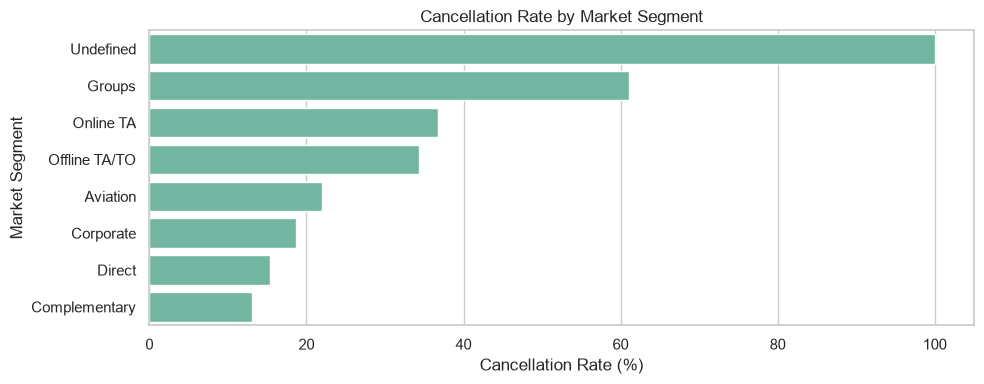

Saved figure: Figures\stay_reservation\market_segment_cancellation_rate.png


In [42]:
plt.figure(figsize=(10, 4))
sns.barplot(
    data=market_segment_summary.sort_values('cancellation_rate', ascending=False),
    x='cancellation_rate',
    y='market_segment'
)
plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Market Segment')
save_current_figure('market_segment_cancellation_rate.png')

In [43]:
market_rates = market_segment_summary.sort_values(
    'cancellation_rate',
    ascending=False
)

print(
    f"Highest cancellation rate: "
    f"{market_rates.iloc[0]['market_segment']} "
    f"({market_rates.iloc[0]['cancellation_rate']:.2f}%)."
)

print(
    f"Lowest cancellation rate: "
    f"{market_rates.iloc[-1]['market_segment']} "
    f"({market_rates.iloc[-1]['cancellation_rate']:.2f}%)."
)

Highest cancellation rate: Undefined (100.00%).
Lowest cancellation rate: Complementary (13.06%).


Finding: Market segments show clear differences in booking volume and cancellation rates. Groups has the highest cancellation rate (61.06%), while Complementary has the lowest (13.06%). The Undefined segment shows 100% cancellation but contains only 2 bookings, so it should be reviewed as a rare category before encoding. market_segment should be retained as a categorical predictor and encoded during preprocessing.

## 3.2 Distribution Channel Analysis

Distribution channel represents the channel through which the booking was distributed or received. This section examines booking volume and cancellation behaviour across distribution channels.

In [40]:
distribution_summary = cancellation_rate_table(
    df,
    'distribution_channel'
)

distribution_summary

,distribution_channel,total_bookings,canceled_bookings,cancellation_rate
4,Undefined,5,4,80.00
3,TA/TO,97870,40152,41.03
0,Corporate,6677,1474,22.08
2,GDS,193,37,19.17
1,Direct,14645,2557,17.46


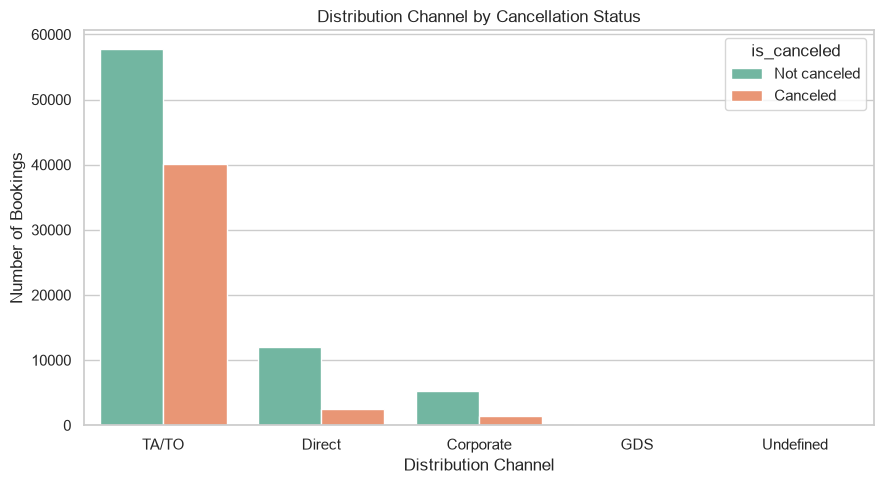

Saved figure: Figures\stay_reservation\distribution_channel_by_cancellation.png


In [41]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='distribution_channel',
    hue='is_canceled',
    order=df['distribution_channel'].value_counts().index
)

plt.title('Distribution Channel by Cancellation Status')
plt.xlabel('Distribution Channel')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])

save_current_figure('distribution_channel_by_cancellation.png')

Finding: Cancellation behaviour differs across distribution channels. TA/TO has the highest cancellation rate (41.03%), while Direct has the lowest (17.46%). The Undefined channel is very rare (5 bookings) and should be reviewed before encoding. distribution_channel should be retained as a categorical predictor during preprocessing.

## 3.3 Deposit Type Analysis

Deposit type describes the deposit arrangement associated with a booking. This analysis examines the distribution of deposit types and their relationship with cancellation behaviour.

In [44]:
deposit_summary = cancellation_rate_table(
    df,
    'deposit_type'
)

deposit_summary

,deposit_type,total_bookings,canceled_bookings,cancellation_rate
1,Non Refund,14587,14494,99.36
0,No Deposit,104641,29694,28.38
2,Refundable,162,36,22.22


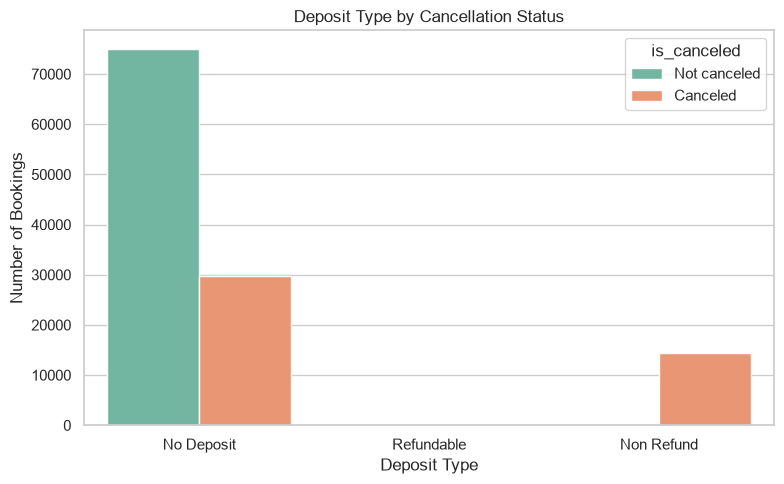

Saved figure: Figures\stay_reservation\deposit_type_by_cancellation.png


In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='deposit_type',
    hue='is_canceled'
)

plt.title('Deposit Type by Cancellation Status')
plt.xlabel('Deposit Type')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])

save_current_figure('deposit_type_by_cancellation.png')

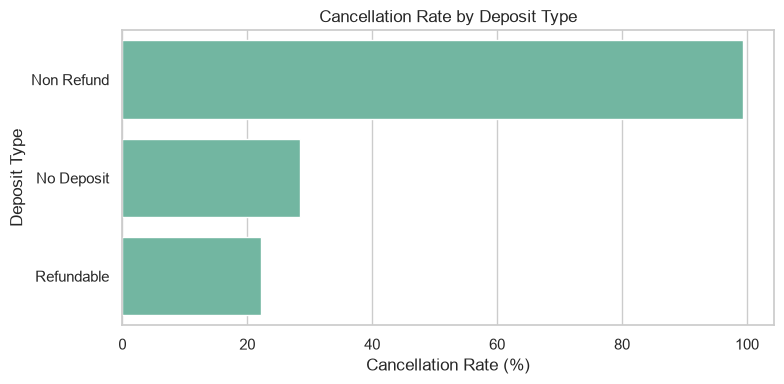

Saved figure: Figures\stay_reservation\deposit_type_cancellation_rate.png


In [46]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=deposit_summary.sort_values('cancellation_rate', ascending=False),
    x='cancellation_rate',
    y='deposit_type'
)
plt.title('Cancellation Rate by Deposit Type')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Deposit Type')
save_current_figure('deposit_type_cancellation_rate.png')

Finding: Deposit type shows a strong relationship with cancellation — Non Refund bookings have a much higher cancellation rate (99.36%) than No Deposit bookings (28.38%). This is an association in the observed data only and does not mean deposit type causes cancellation. Refundable is a rare category (162 bookings, 22.22%) and should be reviewed before encoding. deposit_type should be retained as a categorical predictor.

## 3.4 ADR Distribution & Outliers

ADR (Average Daily Rate) is the average price per night paid for the booking. 
It is the main commercial numerical variable in the dataset. This section 
examines the overall distribution of ADR, investigates outliers and unusual 
values, and compares ADR against the cancellation target.

In [47]:
adr_summary = df['adr'].describe()
adr_summary

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

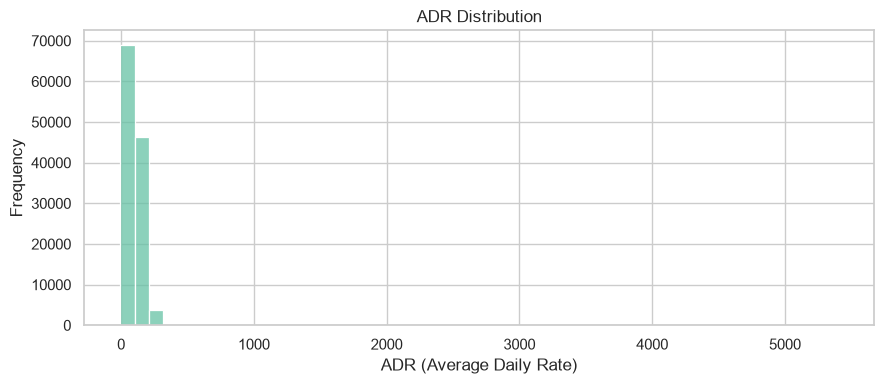

Saved figure: Figures\stay_reservation\adr_distribution.png


In [48]:
plt.figure(figsize=(9, 4))
sns.histplot(df['adr'], bins=50)
plt.title('ADR Distribution')
plt.xlabel('ADR (Average Daily Rate)')
plt.ylabel('Frequency')
save_current_figure('adr_distribution.png')

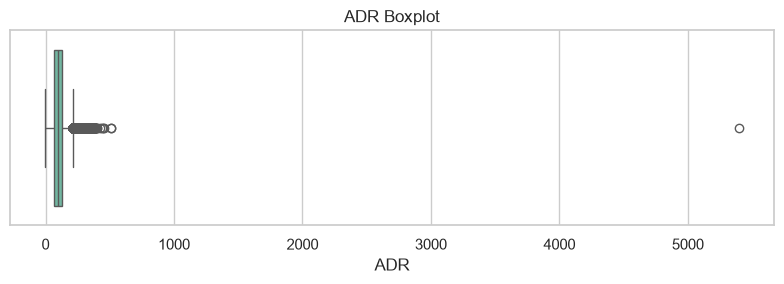

Saved figure: Figures\stay_reservation\adr_boxplot.png


In [49]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['adr'])
plt.title('ADR Boxplot')
plt.xlabel('ADR')
save_current_figure('adr_boxplot.png')

In [50]:
print(f"Bookings with ADR = 0: {(df['adr'] == 0).sum()}")
print(f"Bookings with ADR < 0: {(df['adr'] < 0).sum()}")

Bookings with ADR = 0: 1959
Bookings with ADR < 0: 1


In [51]:
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['adr'] < lower_bound) | (df['adr'] > upper_bound)]

print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
print(f"Number of outlier bookings: {len(outliers)} ({len(outliers) / len(df) * 100:.2f}%)")
print(f"Maximum ADR: {df['adr'].max()}")

Q1: 69.29, Q3: 126.00, IQR: 56.71
Lower bound: -15.77, Upper bound: 211.06
Number of outlier bookings: 3793 (3.18%)
Maximum ADR: 5400.0


In [54]:
adr_cancel_summary = (
    df.groupby('is_canceled')['adr']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .reset_index()
)

adr_cancel_summary

,is_canceled,count,mean,median,min,max
0,0,75166,99.987693,92.5,-6.38,510.0
1,1,44224,104.964333,96.2,0.00,5400.0


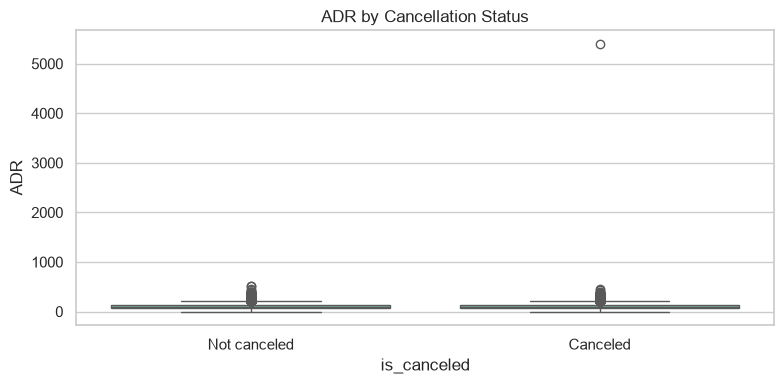

Saved figure: Figures\stay_reservation\adr_by_cancellation.png


In [55]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='is_canceled', y='adr')
plt.title('ADR by Cancellation Status')
plt.xlabel('is_canceled')
plt.ylabel('ADR')
plt.xticks([0, 1], ['Not canceled', 'Canceled'])
save_current_figure('adr_by_cancellation.png')

Finding : ADR ranges from -6.38 to 5400, with most bookings falling between 69.29 and 126.00. The IQR method identifies 3,793 potential outliers (3.18%), mainly at the high end. There are 1,959 bookings with ADR = 0 and 1 negative ADR value, which should be investigated during preprocessing. The mean ADR is slightly higher for canceled bookings (104.96) than for non-canceled bookings (99.99), indicating that ADR may provide useful information for cancellation prediction.
adr should be retained as a numerical predictor. Extreme values should not be automatically removed; their validity should be assessed, and scaling or transformation can be considered during preprocessing.

## 3.5 Country Analysis

Country represents the country of origin of the guest making the booking. It is a high-cardinality categorical variable because it contains many distinct country categories. This section examines the distribution of bookings across countries and compares cancellation rates for countries with sufficiently large booking counts. Cancellation rates for very small countries are interpreted cautiously because a country with very few bookings can show an extreme rate that is not statistically reliable.

In [56]:
country_summary = cancellation_rate_table(
    df,
    'country'
)

country_summary.head(20)

,country,total_bookings,canceled_bookings,cancellation_rate
16,BEN,3,3,100.00
55,FJI,1,1,100.00
118,MYT,2,2,100.00
88,KHM,2,2,100.00
83,JEY,8,8,100.00
74,IMN,2,2,100.00
70,HND,1,1,100.00
122,NIC,1,1,100.00
167,UMI,1,1,100.00
172,VGB,1,1,100.00


In [57]:
print("Number of unique countries:", df['country'].nunique())
print("Missing country values:", df['country'].isna().sum())

Number of unique countries: 177
Missing country values: 488


In [58]:
top_countries = (
    df['country']
    .value_counts()
    .head(15)
    .reset_index()
)

top_countries.columns = ['country', 'bookings']

top_countries

,country,bookings
0,PRT,48590
1,GBR,12129
2,FRA,10415
3,ESP,8568
4,DEU,7287
5,ITA,3766
6,IRL,3375
7,BEL,2342
8,BRA,2224
9,NLD,2104


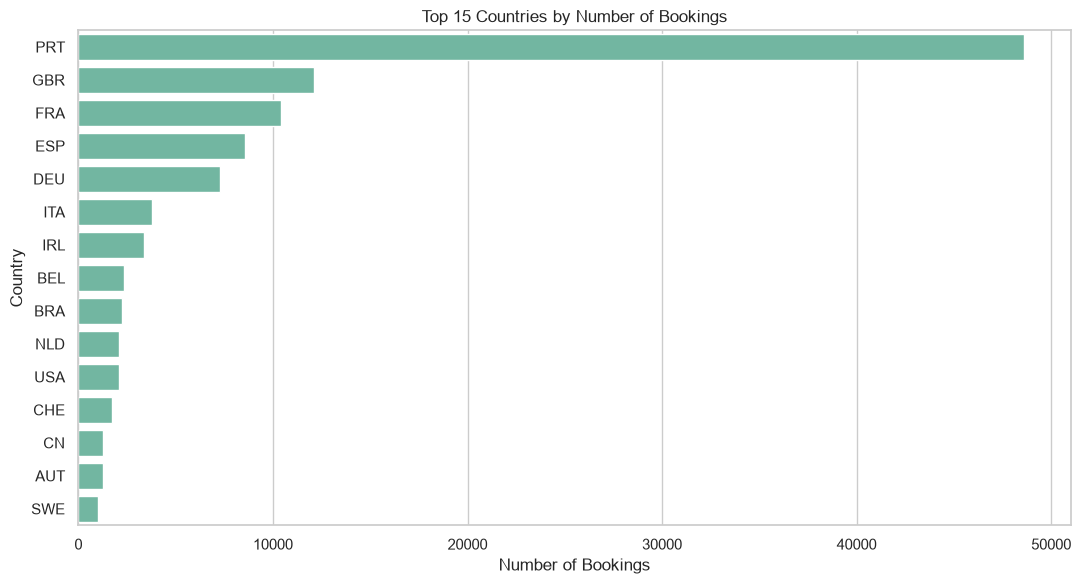

Saved figure: Figures\stay_reservation\top_15_countries.png


In [59]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_countries,
    x='bookings',
    y='country'
)

plt.title('Top 15 Countries by Number of Bookings')
plt.xlabel('Number of Bookings')
plt.ylabel('Country')

save_current_figure('top_15_countries.png')

In [60]:
country_cancel = cancellation_rate_table(df, 'country')

country_cancel_filtered = country_cancel[
    country_cancel['total_bookings'] >= 100
].sort_values('cancellation_rate', ascending=False).head(15)

country_cancel_filtered

,country,total_bookings,canceled_bookings,cancellation_rate
135,PRT,48590,27519,56.64
1,AGO,362,205,56.63
31,CHN,999,462,46.25
103,MAR,259,109,42.08
91,KOR,133,55,41.35
162,TUR,248,102,41.13
100,LUX,287,109,37.98
140,RUS,632,239,37.82
25,BRA,2224,830,37.32
81,ITA,3766,1333,35.40


**Finding** : `country` is a high-cardinality categorical variable with **177 unique countries** and **488 missing values**. Most bookings are concentrated in a few countries, with **PRT (Portugal)** having the highest number of bookings.
Cancellation rates vary across countries, but rates for countries with very few bookings may be unreliable. Therefore, rare countries should be handled carefully during preprocessing, such as grouping them into an `Other` category or using a suitable encoding method.

## 3.6 Agent & Company Analysis

Agent and company represent the travel agency and corporate company associated 
with each booking. Both are high-cardinality identifier-like categorical 
variables and both contain substantial missing values. This section examines 
their cardinality, missingness, and booking distributions.

An important consideration is that a missing agent or company value may not be 
a random data-quality failure — it may indicate that the booking was made 
without an agent (e.g., directly) or without a corporate affiliation. The 
missingness itself may therefore carry meaning.

In [61]:
df['adr'].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

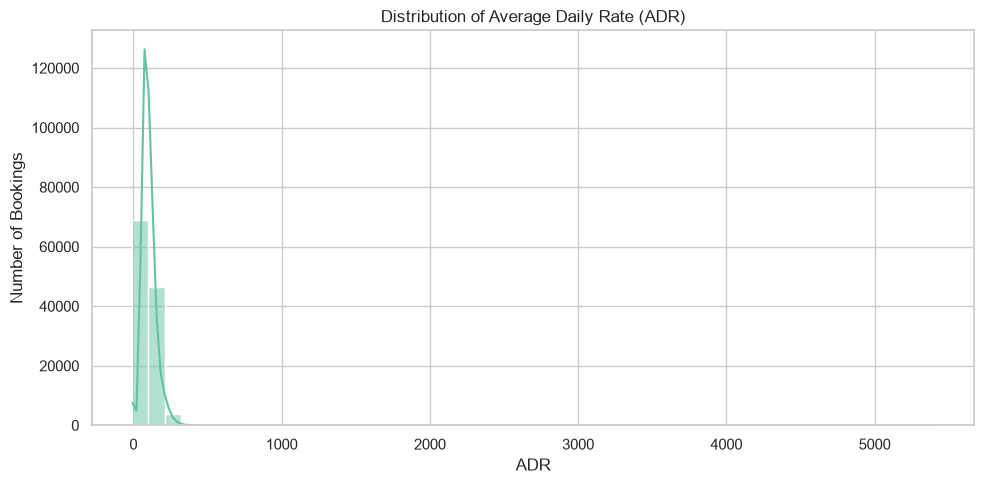

Saved figure: Figures\stay_reservation\adr_distribution.png


In [62]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='adr',
    bins=50,
    kde=True
)

plt.title('Distribution of Average Daily Rate (ADR)')
plt.xlabel('ADR')
plt.ylabel('Number of Bookings')

save_current_figure('adr_distribution.png')

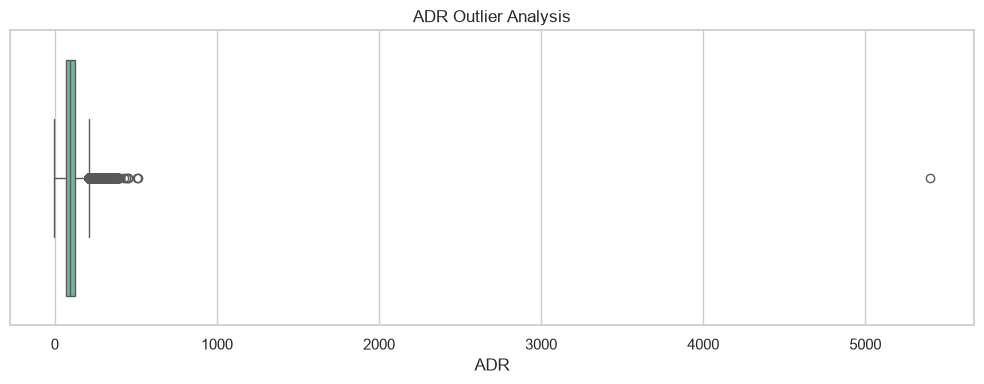

Saved figure: Figures\stay_reservation\adr_boxplot.png


In [63]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x='adr'
)

plt.title('ADR Outlier Analysis')
plt.xlabel('ADR')

save_current_figure('adr_boxplot.png')

In [64]:
print("ADR minimum:", df['adr'].min())
print("ADR maximum:", df['adr'].max())
print("ADR zero values:", (df['adr'] == 0).sum())
print("ADR negative values:", (df['adr'] < 0).sum())

ADR minimum: -6.38
ADR maximum: 5400.0
ADR zero values: 1959
ADR negative values: 1


In [65]:
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

adr_outliers = df[
    (df['adr'] < lower_bound) |
    (df['adr'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of ADR outliers:", len(adr_outliers))

Q1: 69.29
Q3: 126.0
IQR: 56.709999999999994
Lower bound: -15.774999999999991
Upper bound: 211.065
Number of ADR outliers: 3793


In [66]:
adr_cancel_summary = (
    df.groupby('is_canceled')['adr']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .reset_index()
)

adr_cancel_summary

,is_canceled,count,mean,median,min,max
0,0,75166,99.987693,92.5,-6.38,510.0
1,1,44224,104.964333,96.2,0.00,5400.0


**Finding** : `agent` and `company` are high-cardinality categorical variables with substantial missing values. Missing values may represent bookings made without an agent or company rather than random missing data. Therefore, missingness should be handled carefully, and rare categories may need to be grouped or encoded using a suitable method.


## 3.7 Assigned Room Type Analysis

Assigned room type represents the room type assigned to the booking. This 
section examines its distribution and relationship with cancellation status.

The variable is also compared with `reserved_room_type` (analyzed by Member 2) 
because differences between the reserved and assigned room type may represent 
changes in the reservation and may provide a potential feature-engineering 
opportunity.

In [67]:
assigned_room_summary = cancellation_rate_table(
    df,
    'assigned_room_type'
)

assigned_room_summary

,assigned_room_type,total_bookings,canceled_bookings,cancellation_rate
11,P,12,12,100.00
10,L,1,1,100.00
0,A,74053,32948,44.49
7,H,712,251,35.25
6,G,2553,780,30.55
4,E,7806,1968,25.21
3,D,25322,6362,25.12
5,F,3751,927,24.71
1,B,2163,512,23.67
2,C,2375,446,18.78


In [70]:
print(
    "Missing assigned_room_type values:",
    df['assigned_room_type'].isna().sum()
)

Missing assigned_room_type values: 0


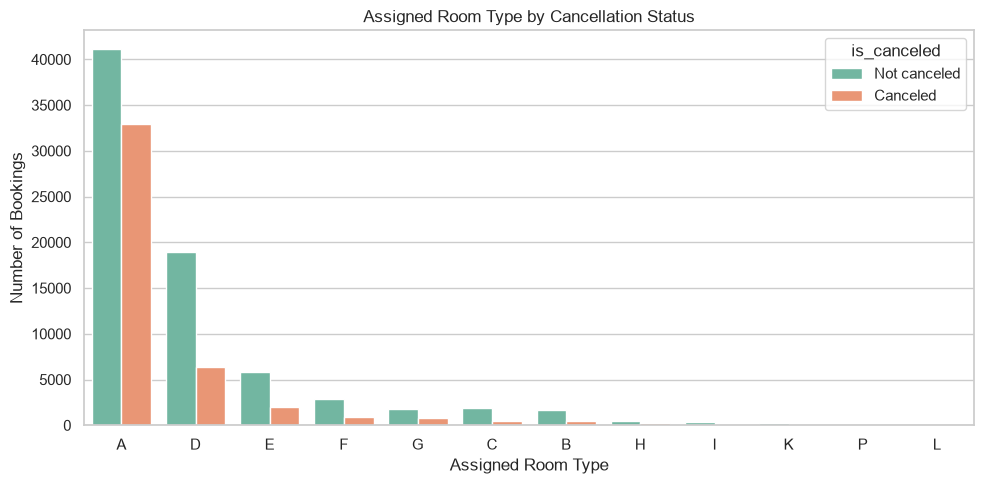

Saved figure: Figures\stay_reservation\assigned_room_type_by_cancellation.png


In [71]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='assigned_room_type',
    hue='is_canceled',
    order=df['assigned_room_type'].value_counts().index
)

plt.title('Assigned Room Type by Cancellation Status')
plt.xlabel('Assigned Room Type')
plt.ylabel('Number of Bookings')
plt.legend(
    title='is_canceled',
    labels=['Not canceled', 'Canceled']
)

save_current_figure('assigned_room_type_by_cancellation.png')

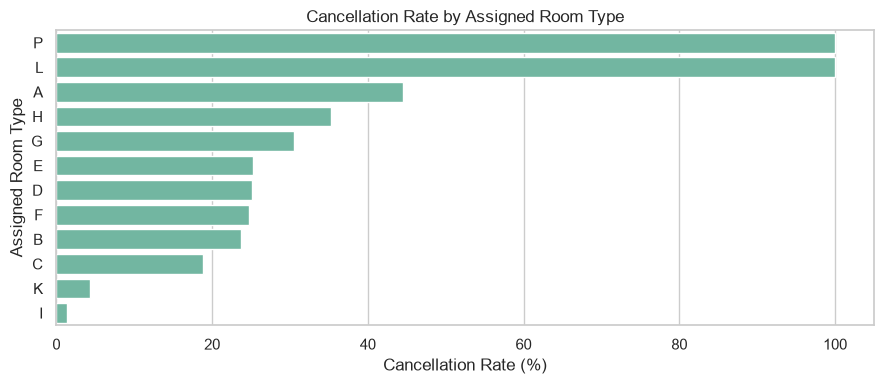

Saved figure: Figures\stay_reservation\assigned_room_cancellation_rate.png


In [72]:
plt.figure(figsize=(9, 4))

sns.barplot(
    data=assigned_room_summary.sort_values(
        'cancellation_rate',
        ascending=False
    ),
    x='cancellation_rate',
    y='assigned_room_type'
)

plt.title('Cancellation Rate by Assigned Room Type')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Assigned Room Type')

save_current_figure('assigned_room_cancellation_rate.png')

In [73]:
room_type_changed = (
    df['reserved_room_type'] != df['assigned_room_type']
)

room_change_summary = (
    pd.DataFrame({
        'room_type_changed': room_type_changed,
        'is_canceled': df['is_canceled']
    })
    .groupby('room_type_changed')['is_canceled']
    .agg(
        total_bookings='count',
        canceled_bookings='sum',
        cancellation_rate='mean'
    )
    .reset_index()
)

room_change_summary['cancellation_rate'] = (
    room_change_summary['cancellation_rate'] * 100
).round(2)

room_change_summary

,room_type_changed,total_bookings,canceled_bookings,cancellation_rate
0,False,104473,43422,41.56
1,True,14917,802,5.38


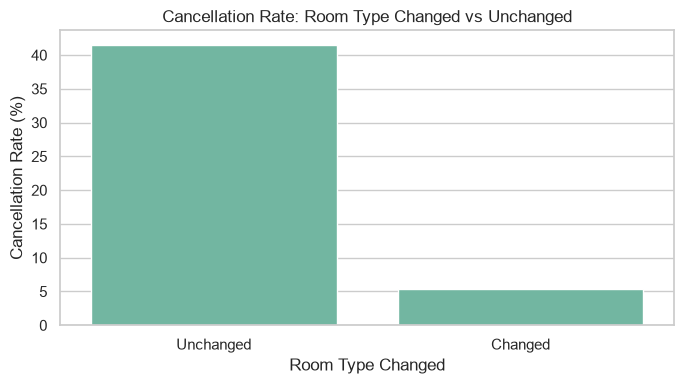

Saved figure: Figures\stay_reservation\room_type_change_cancellation.png


In [74]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=room_change_summary,
    x='room_type_changed',
    y='cancellation_rate'
)

plt.title('Cancellation Rate: Room Type Changed vs Unchanged')
plt.xlabel('Room Type Changed')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(
    [0, 1],
    ['Unchanged', 'Changed']
)

save_current_figure('room_type_change_cancellation.png')

Finding : Assigned room types show differences in booking volume and cancellation rates 
across room categories, indicating that `assigned_room_type` may provide useful 
information for cancellation prediction.
The comparison between reserved and assigned room types also identifies 
bookings where the assigned room differs from the reserved room. This may 
provide a potential feature-engineering opportunity. However, the timing of 
room assignment should be established before including `assigned_room_type` 
or the derived `room_type_changed` feature in the final model to avoid using 
information that may not have been available at the intended prediction point.
Missing values should also be reviewed during preprocessing.

## 3.8 Overall Numerical Correlation Analysis

This section examines linear correlations between all numerical variables in 
the dataset. Because the target `is_canceled` is binary, its correlations with 
numerical predictors should be interpreted as associations rather than causal 
relationships. Categorical variables are not included in this analysis.

The purpose is to identify predictors associated with cancellation and to 
detect highly correlated predictor pairs that may indicate redundancy or 
multicollinearity.

In [78]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

numeric_columns

Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='str')

In [79]:
correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
is_canceled,1.000000,0.293123,0.016660,0.008148,-0.006130,-0.001791,0.024765,0.060017,0.005048,-0.032491,-0.084793,0.110133,-0.057358,-0.144381,-0.083114,-0.020642,0.054186,0.047557,-0.195498,-0.234658
lead_time,0.293123,1.000000,0.040142,0.126871,0.002268,0.085671,0.165799,0.119519,-0.037622,-0.020915,-0.124410,0.086042,-0.073548,0.000149,-0.069741,0.151464,0.170084,-0.063077,-0.116451,-0.095712
arrival_date_year,0.016660,0.040142,1.000000,-0.540561,-0.000221,0.021497,0.030883,0.029635,0.054624,-0.013192,0.010341,-0.119822,0.029218,0.030872,0.063457,0.259095,-0.056497,0.197580,-0.013684,0.108531
arrival_date_week_number,0.008148,0.126871,-0.540561,1.000000,0.066809,0.018208,0.015558,0.025909,0.005518,0.010395,-0.030131,0.035501,-0.020904,0.005508,-0.031201,-0.076760,0.022933,0.075791,0.001920,0.026149
arrival_date_day_of_month,-0.006130,0.002268,-0.000221,0.066809,1.000000,-0.016354,-0.028174,-0.001566,0.014544,-0.000230,-0.006145,-0.027011,-0.000300,0.010613,0.001487,0.044858,0.022728,0.030245,0.008683,0.003062
stays_in_weekend_nights,-0.001791,0.085671,0.021497,0.018208,-0.016354,1.000000,0.498969,0.091871,0.045793,0.018483,-0.087239,-0.012775,-0.042715,0.063281,0.140739,0.066749,-0.054151,0.049342,-0.018554,0.072671
stays_in_week_nights,0.024765,0.165799,0.030883,0.015558,-0.028174,0.498969,1.000000,0.092976,0.044203,0.020191,-0.097245,-0.013992,-0.048743,0.096209,0.182382,0.182211,-0.002020,0.065237,-0.024859,0.068192
adults,0.060017,0.119519,0.029635,0.025909,-0.001566,0.091871,0.092976,1.000000,0.030447,0.018146,-0.146426,-0.006738,-0.107983,-0.051673,-0.035594,0.207793,-0.008283,0.230641,0.014785,0.122884
children,0.005048,-0.037622,0.054624,0.005518,0.014544,0.045793,0.044203,0.030447,1.000000,0.024030,-0.032859,-0.024730,-0.021072,0.048949,0.041066,0.030931,-0.033273,0.324854,0.056253,0.081745
babies,-0.032491,-0.020915,-0.013192,0.010395,-0.000230,0.018483,0.020191,0.018146,0.024030,1.000000,-0.008943,-0.007501,-0.006550,0.083440,0.036184,0.019206,-0.010621,0.029186,0.037383,0.097889


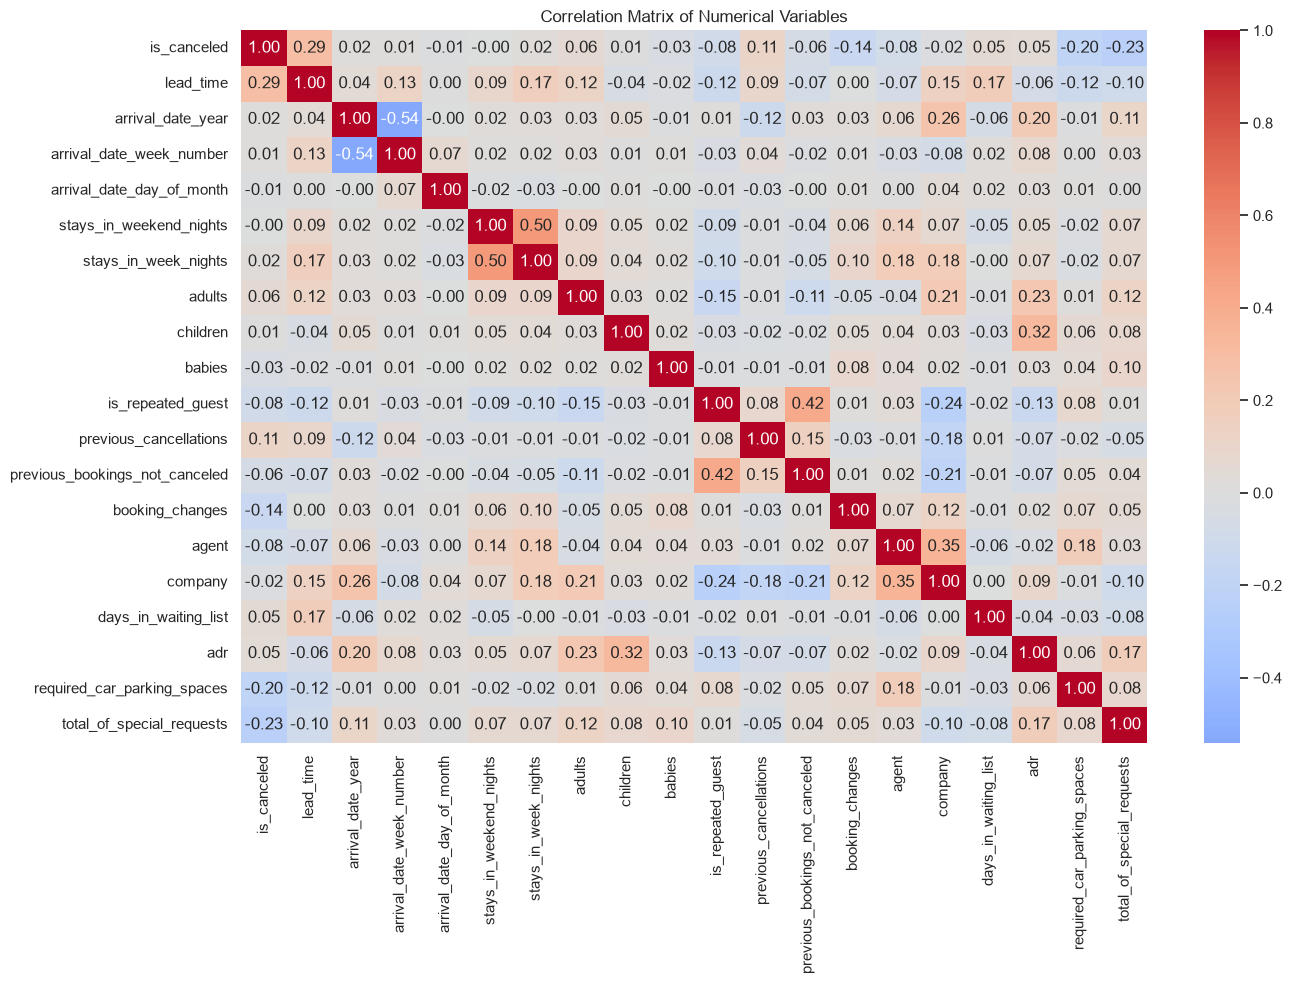

Saved figure: Figures\stay_reservation\numerical_correlation_matrix.png


In [80]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Numerical Variables')

save_current_figure('numerical_correlation_matrix.png')

In [81]:
target_correlations = (
    correlation_matrix['is_canceled']
    .drop('is_canceled')
    .sort_values(key=abs, ascending=False)
)

target_correlations

lead_time                         0.293123
total_of_special_requests        -0.234658
required_car_parking_spaces      -0.195498
booking_changes                  -0.144381
previous_cancellations            0.110133
is_repeated_guest                -0.084793
agent                            -0.083114
adults                            0.060017
previous_bookings_not_canceled   -0.057358
days_in_waiting_list              0.054186
adr                               0.047557
babies                           -0.032491
stays_in_week_nights              0.024765
company                          -0.020642
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
arrival_date_day_of_month        -0.006130
children                          0.005048
stays_in_weekend_nights          -0.001791
Name: is_canceled, dtype: float64

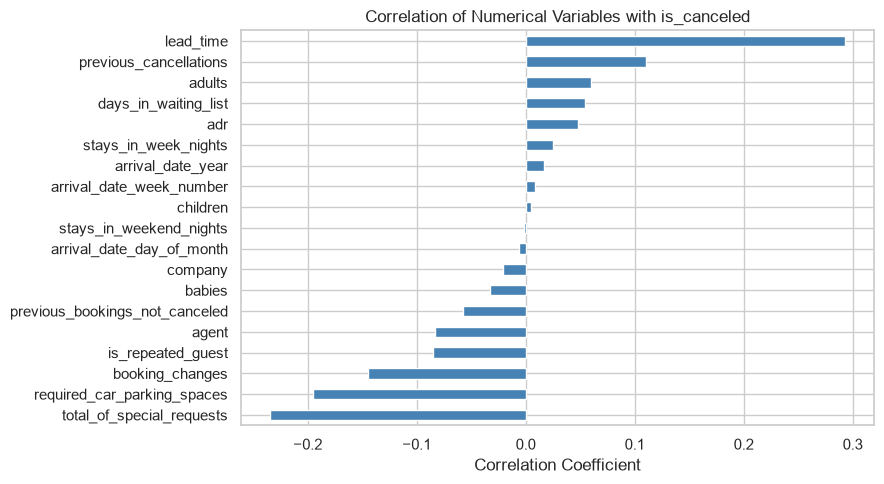

Saved figure: Figures\stay_reservation\target_correlations.png


In [84]:
plt.figure(figsize=(9, 5))

target_correlations.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Correlation of Numerical Variables with is_canceled')
plt.xlabel('Correlation Coefficient')

save_current_figure('target_correlations.png')

Finding : The numerical correlation matrix provides an overall view of linear 
relationships among the numerical variables. Correlations with `is_canceled` 
represent associations in the observed dataset and should not be interpreted 
as evidence of causation.
The variables with the strongest positive and negative correlations with 
`is_canceled` can be identified from the target-correlation table above. ADR 
shows a relatively weak correlation with cancellation, which is consistent 
with the distributional analysis in Section 3.4.
The correlation matrix should also be reviewed for highly correlated 
predictor pairs, as strong relationships may indicate redundancy. However, 
correlation only measures linear relationships, so weaker correlations do 
not necessarily mean that a variable has no predictive value.

## 3.9 Missing-Value Pattern Analysis

Missing-value patterns were examined to identify variables that require special handling during preprocessing. The analysis found missing values in four variables: company, agent, country, and children.

In [85]:
missing_summary = (
    df.isnull()
      .sum()
      .to_frame('missing_count')
)

missing_summary['missing_percentage'] = (
    missing_summary['missing_count'] / len(df) * 100
).round(2)

missing_summary = (
    missing_summary[
        missing_summary['missing_count'] > 0
    ]
    .sort_values('missing_percentage', ascending=False)
)

missing_summary

,missing_count,missing_percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


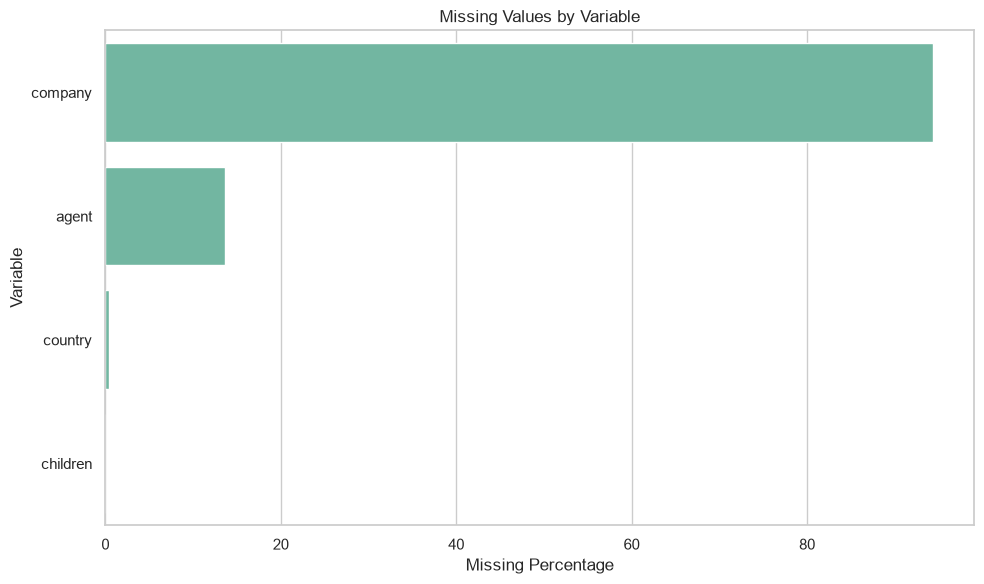

Saved figure: Figures\stay_reservation\missing_value_percentage.png


In [86]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=missing_summary.reset_index(),
    x='missing_percentage',
    y='index'
)

plt.title('Missing Values by Variable')
plt.xlabel('Missing Percentage')
plt.ylabel('Variable')

save_current_figure('missing_value_percentage.png')

Finding : The missing-value analysis shows that company has very high missingness (94.31%), while agent has 13.69% missing values. country has only 0.41% missing values, and children has only 4 missing records.
The missing values should be handled according to the characteristics of each variable rather than using a single strategy. The high missingness in company should be carefully evaluated before deciding whether to retain or remove the variable. Missing values in agent and country can be handled using suitable categorical-value strategies, while the four missing children values can be handled with an appropriate numerical imputation method

## 3.10 Data Leakage Investigation

Data leakage occurs when information that would not be available at the time a prediction is made is used as a predictive feature. This can result in unrealistically high model performance.

This section investigates `reservation_status` and `reservation_status_date`, which are potentially problematic because they describe the eventual reservation outcome or information recorded after the booking process.

In [87]:
reservation_status_summary = cancellation_rate_table(
    df,
    'reservation_status'
)

reservation_status_summary

,reservation_status,total_bookings,canceled_bookings,cancellation_rate
0,Canceled,43017,43017,100.0
2,No-Show,1207,1207,100.0
1,Check-Out,75166,0,0.0


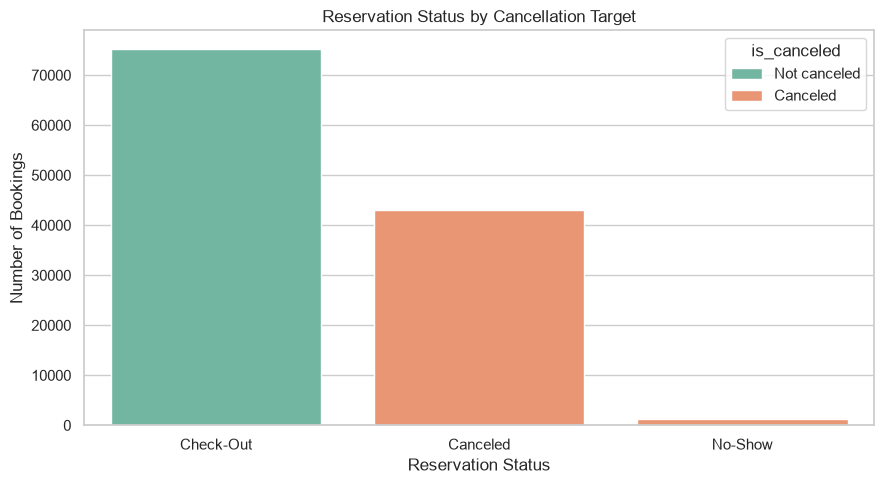

Saved figure: Figures\stay_reservation\reservation_status_by_cancellation.png


In [88]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='reservation_status',
    hue='is_canceled'
)

plt.title('Reservation Status by Cancellation Target')
plt.xlabel('Reservation Status')
plt.ylabel('Number of Bookings')
plt.legend(title='is_canceled', labels=['Not canceled', 'Canceled'])

save_current_figure('reservation_status_by_cancellation.png')

In [89]:
pd.crosstab(
    df['reservation_status'],
    df['is_canceled'],
    normalize='index'
).round(3)

is_canceled,0,1
reservation_status,,
Canceled,0.0,1.0
Check-Out,1.0,0.0
No-Show,0.0,1.0


In [90]:
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

df['reservation_status_date'].describe()

count                        119390
mean     2016-07-30 00:24:47.883407
min             2014-10-17 00:00:00
25%             2016-02-01 00:00:00
50%             2016-08-07 00:00:00
75%             2017-02-08 00:00:00
max             2017-09-14 00:00:00
Name: reservation_status_date, dtype: object

In [91]:
status_date_by_target = (
    df.groupby('is_canceled')['reservation_status_date']
      .agg(['min', 'max'])
)

status_date_by_target

,min,max
is_canceled,,
0,2015-07-01,2017-09-14
1,2014-10-17,2017-08-31


In [92]:
print(
    "Missing reservation_status_date:",
    df['reservation_status_date'].isna().sum()
)

Missing reservation_status_date: 0


Finding : `reservation_status` has a direct relationship with `is_canceled`. **Canceled** and **No-Show** bookings have 100% cancellation, while **Check-Out** bookings have 0% cancellation. Therefore, this variable reveals the final outcome and causes data leakage.
`reservation_status_date` also represents information recorded about the reservation status and may not be available at prediction time.
**Therefore, both `reservation_status` and `reservation_status_date` should be removed before model training to prevent data leakage.**


## 3.11 Temporal Leakage Investigation

In addition to reservation_status and reservation_status_date, other variables were investigated to determine whether they may contain information generated after the original booking. Such variables can introduce temporal leakage if the prediction is intended to be made at the time of booking.

The following variables were considered:

assigned_room_type
booking_changes
days_in_waiting_list
reservation_status
reservation_status_date
Investigation

The number of bookings involving room type changes and booking changes was examined:

In [94]:
print( "Bookings with room type changes:", df['room_type_changed'].sum() 
      ) 
print( "Bookings with booking changes:", (df['booking_changes'] > 0).sum() 
      )

Bookings with room type changes: 14917
Bookings with booking changes: 18076


Finding : reservation_status and reservation_status_date contain information related to the later reservation outcome and can cause temporal leakage.
assigned_room_type, booking_changes, and days_in_waiting_list may be valid predictors if they are known at the prediction time. Therefore, their timing should be considered before including them in the model.

## 3.12 Member 3 Preprocessing and Feature-Engineering Implications

Based on the EDA findings, the following preprocessing and feature-engineering steps should be considered:

* Encode categorical variables such as `market_segment`, `distribution_channel`, `deposit_type`, and `assigned_room_type`.
* Review rare categories in high-cardinality variables such as `country`, `agent`, and `company`.
* Handle missing values in `agent`, `company`, and `country` appropriately.
* Retain `adr` as a numerical feature while checking its skewness, zero values, and extreme observations.
* Do not remove `adr` outliers automatically, as they may represent genuine booking conditions.
* Consider grouping rare categories into an `Other` category or using a suitable encoding method.
* Review correlations among numerical variables for possible redundancy.
* Treat correlations with `is_canceled` as associations, not causal relationships.
* Exclude `reservation_status` and `reservation_status_date` to prevent data leakage.
* Review the temporal availability of `assigned_room_type` and `booking_changes` before including them in the model.
* Ensure that any feature engineering based on booking history, room assignment, or reservation changes uses only information available at the intended prediction time.


## Overall EDA Conclusion and Recommendations (To Be Completed After All Members Finish)

This section should combine Member 1, Member 2, and Member 3 findings into one final EDA conclusion and preprocessing/feature-engineering recommendation section.